# Tahap 2 — Data Audit, Data Understanding & EDA

Notebook utama penelitian ABSA BrewScope di Kecamatan Jatinangor. Pilih kernel **BrewScope (.venv)** dan jalankan **Run All**. Data mentah dipertahankan; artefak disimpan ke reports/ dan flag ke data/interim/.

## 1. Research Context & Analysis Objectives

**Tujuan.** Mengukur kualitas, keterwakilan kedai, karakteristik teks, ketimpangan rating, serta indikasi enam kandidat aspek untuk merancang Tahap 3.

**Metode.** Audit seluruh CSV secara deterministik. Kedai diidentifikasi melalui place ID/URL. Duplikasi rekaman dibedakan dari ungkapan berulang. Keyword matching hanya digunakan untuk eksplorasi cakupan aspek.

**Implikasi.** Label sentimen aspek harus ditentukan pada tahap berikutnya; rating bintang bukan ground truth sentimen aspek. Aspek tidak disebutkan berbeda dari sentimen netral.


In [1]:
for objective in (
    "Audit kelengkapan dan validitas enam kolom",
    "Bedakan duplikasi rekaman dan pengulangan ungkapan",
    "Ukur distribusi kedai, rating, dan panjang teks",
    "Eksplorasi enam aspek untuk rancangan labeling",
):
    print("•", objective)


• Audit kelengkapan dan validitas enam kolom
• Bedakan duplikasi rekaman dan pengulangan ungkapan
• Ukur distribusi kedai, rating, dan panjang teks
• Eksplorasi enam aspek untuk rancangan labeling


## 2. Environment Setup & Data Loading

**Tujuan.** Menetapkan sumber, environment, dan parameter yang dapat direproduksi.

**Metode.** Instal dependency dengan `pip install -e ".[analysis,dev]"`. Root ditemukan melalui pyproject.toml dan PROJECT_CONTEXT.md. Semua kolom CSV dibaca sebagai string, termasuk string kosong; tanggal acuan ditetapkan eksplisit. SHA-256 sumber diperiksa pada akhir eksekusi.

**Hasil dan interpretasi.** Versi package serta checksum menjadi provenance analisis. Notebook tidak membaca token atau memanggil API.


In [2]:
import hashlib
import importlib.metadata
import json
import platform
import re
from pathlib import Path
from urllib.parse import parse_qs, unquote, urlsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
PROJECT_ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "pyproject.toml").is_file() and (p / "PROJECT_CONTEXT.md").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Jalankan dari root repository atau notebooks/.")
RAW_PATH = PROJECT_ROOT / "data/raw/google_maps_reviews_jatinangor_raw.csv"
REPORTS = PROJECT_ROOT / "reports"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
FLAGS_PATH = PROJECT_ROOT / "data/interim/review_audit_flags.csv"
AUDIT_CUTOFF = pd.Timestamp("2026-10-25T23:59:59+07:00")
SHORT_WORD_LIMIT = 4
MIN_PLACE_REVIEWS = 30
RARE_ASPECT_PCT = 5.0
SEED = 42
VERSIONS = {p: importlib.metadata.version(p) for p in
            ("pandas", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel")}
VERSIONS["python"] = platform.python_version()
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.grid": False,
})
COLORS = {"main": "#326A7A", "warn": "#C48831", "dark": "#47362D"}
for directory in (TABLES, FIGURES, FLAGS_PATH.parent):
    directory.mkdir(parents=True, exist_ok=True)
if not RAW_PATH.is_file():
    raise FileNotFoundError(f"Input tidak ditemukan: {RAW_PATH.relative_to(PROJECT_ROOT)}")
SOURCE_SHA256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
# Revisi narasi/readiness tidak menulis ulang PNG yang perhitungannya tetap sama.
FORCE_REBUILD_FIGURES = False
previous_summary_path = REPORTS / "data_audit_summary.json"
previous_summary = (
    json.loads(previous_summary_path.read_text(encoding="utf-8"))
    if previous_summary_path.is_file() else {}
)
raw = pd.read_csv(RAW_PATH, dtype="string", keep_default_na=False)
display(pd.Series(VERSIONS, name="versi").to_frame())
print("Input:", RAW_PATH.relative_to(PROJECT_ROOT).as_posix())
print("SHA-256:", SOURCE_SHA256)


,versi
pandas,2.3.3
numpy,2.4.6
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0
python,3.11.9


Input: data/raw/google_maps_reviews_jatinangor_raw.csv
SHA-256: 7b87a53110041da74e976a6c9cb121c1dea7d73be70daeab58b2c07bef775719


### Fungsi audit dan aturan eksplorasi

Fungsi analisis tetap berada pada cell bertag **audit-core** agar notebook mandiri; pytest memanggil fungsi yang sama.

Identitas kedai diprioritaskan dari query_place_id, token !1s, CID, lalu URL Maps yang dinormalisasi. Nama tidak menjadi satu-satunya dasar penggabungan. URL pencarian tanpa ID/URL pendek tetap ambigu dan ditandai. Wilayah administratif belum dapat diverifikasi dari enam kolom ini.

**Duplikasi rekaman terkonfirmasi** berarti keenam field sumber identik, bukan bukti dua pelanggan adalah orang yang sama. ID sama dengan field berbeda adalah konflik. Teks sama antar-ID merupakan kandidat duplikasi/pengulangan yang harus ditinjau, bukan langsung dihapus.


In [3]:
REQUIRED_COLUMNS = (
    "review_id", "nama_tempat", "rating", "tanggal_review", "teks_review", "url_tempat"
)
ASPECT_KEYWORDS = {
    "Product Quality": (
        "kopi", "kopinya", "coffee", "espresso", "latte", "cappuccino", "minuman",
        "minumannya", "makanan", "makanannya", "menu", "rasanya", "rasa",
        "matcha", "croissant", "pastry", "roti", "snack",
    ),
    "Service": (
        "pelayanan", "pelayanannya", "layanan", "service", "staff", "staf",
        "barista", "kasir", "ramah", "antre", "antri", "antrean", "antrian",
        "nunggu", "menunggu", "pesanan", "waktu tunggu", "waiter", "waitress",
    ),
    "Price & Value": (
        "harga", "harganya", "price", "murah", "mahal", "terjangkau",
        "affordable", "worth it", "value for money", "promo", "diskon", "budget",
    ),
    "Ambience": (
        "suasana", "suasananya", "nyaman", "nyamannya", "cozy", "ambience",
        "ambiance", "interior", "berisik", "bising", "tenang", "nongkrong",
        "nugas", "estetik", "aesthetic", "view", "pemandangan", "musik",
    ),
    "Facilities": (
        "wifi", "wi fi", "wi-fi", "internet", "parkir", "parkirnya", "stopkontak",
        "stop kontak", "colokan", "toilet", "wc", "ac", "air conditioner",
        "mushola", "musala", "kursi", "meja", "fasilitas",
    ),
    "Cleanliness": (
        "bersih", "bersihnya", "kebersihan", "kebersihannya", "kotor", "jorok",
        "higienis", "hygiene", "clean", "cleanliness", "sampah", "debu", "berdebu", "lengket",
    ),
}
ASPECT_PATTERNS = {
    aspect: re.compile(
        r"(?<!\w)(?:" + "|".join(
            re.escape(keyword).replace(r"\ ", r"\s+")
            for keyword in sorted(keywords, key=len, reverse=True)
        ) + r")(?!\w)", re.IGNORECASE,
    )
    for aspect, keywords in ASPECT_KEYWORDS.items()
}
EMAIL_PATTERN = re.compile(r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}")
PHONE_PATTERN = re.compile(r"(?<!\w)(?:\+62|62|0)8\d(?:[\s-]?\d){7,11}(?!\w)")
ID_HINTS = {"dan", "yang", "di", "ini", "untuk", "kopi", "kopinya", "tempat",
            "enak", "nyaman", "harga", "pelayanan", "makanan", "banget", "tidak"}
EN_HINTS = {"the", "and", "very", "good", "great", "nice", "place", "with", "friendly"}
SLANG_HINTS = {"gak", "ga", "nggak", "bgt", "banget", "nugas", "nongki", "mantul", "enakeun"}
IRRELEVANCE_PATTERN = re.compile(
    r"(?<!\w)(?:pinjol|slot gacor|judi online|jual akun|klik link)(?!\w)", re.IGNORECASE,
)


def normalize_text(value):
    return re.sub(r"\s+", " ", str(value)).strip().casefold()


def redact(text):
    return PHONE_PATTERN.sub("[TELEPON]", EMAIL_PATTERN.sub("[EMAIL]", str(text)))


def place_identity(value):
    """Identitas, validitas URL Maps, dan kekuatan identitas; tanpa jaringan."""
    try:
        parsed = urlsplit(str(value).strip())
        host = (parsed.hostname or "").lower()
    except ValueError:
        return "", False, "invalid"
    google_host = bool(re.fullmatch(r"(?:www\.|maps\.)?google\.(?:com|co\.id|[a-z]{2})", host))
    maps_path = parsed.path == "/maps" or parsed.path.startswith("/maps/")
    short_maps = host == "maps.app.goo.gl" or (host == "goo.gl" and maps_path)
    valid = parsed.scheme in {"http", "https"} and ((google_host and maps_path) or short_maps)
    if not valid:
        return "", False, "invalid"
    query = parse_qs(parsed.query)
    place_id = query.get("query_place_id", query.get("place_id", [""]))[0]
    if place_id:
        return "place_id:" + place_id, True, "place_id"
    token = re.search(r"!1s([^!/?]+)", unquote(parsed.path))
    if token:
        return "maps_id:" + token.group(1), True, "maps_id"
    if query.get("cid"):
        return "cid:" + query["cid"][0], True, "cid"
    canonical = unquote(parsed.path).rstrip("/")
    if canonical.startswith("/maps/place/"):
        return "maps_path:" + canonical, True, "path_needs_review"
    search = query.get("query", query.get("q", [""]))[0]
    return "maps_url:" + host + canonical + ":" + normalize_text(search), True, "ambiguous"


def audit_reviews(frame, cutoff=AUDIT_CUTOFF):
    missing = set(REQUIRED_COLUMNS) - set(frame.columns)
    if missing:
        raise ValueError("Kolom wajib hilang: " + ", ".join(sorted(missing)))
    if frame.empty:
        raise ValueError("Dataset kosong; audit memerlukan minimal satu review.")
    source = frame.reset_index(drop=True).copy(deep=True)
    a = source.copy(deep=True)
    a["source_row_number"] = np.arange(2, len(a) + 2)
    blank = pd.DataFrame(index=a.index)
    for column in REQUIRED_COLUMNS:
        blank[column] = a[column].isna() | a[column].astype("string").str.strip().eq("").fillna(True)
        a["missing_" + column] = blank[column]
    a["missing_required"] = blank.any(axis=1)
    text = a["teks_review"].fillna("").astype(str)
    a["normalized_text"] = text.map(normalize_text)
    a["char_count"] = text.str.len()
    a["word_count"] = text.map(lambda s: len(re.findall(r"\b[^\W_]+(?:[-'][^\W_]+)*\b", s)))
    a["is_empty_text"] = a["missing_teks_review"]
    a["is_short_review"] = a["word_count"].lt(SHORT_WORD_LIMIT) & ~a["is_empty_text"]
    a["is_symbol_only"] = text.map(lambda s: bool(s.strip()) and not any(c.isalnum() for c in s))
    a["is_potentially_irrelevant"] = text.str.contains(IRRELEVANCE_PATTERN, na=False)
    a["has_email"] = text.str.contains(EMAIL_PATTERN, na=False)
    a["has_phone"] = text.str.contains(PHONE_PATTERN, na=False)
    a["needs_privacy_review"] = a["has_email"] | a["has_phone"]
    tokens = text.str.casefold().map(lambda s: set(re.findall(r"\b\w+\b", s)))
    a["has_id_hint"] = tokens.map(lambda s: bool(s & ID_HINTS))
    a["has_en_hint"] = tokens.map(lambda s: bool(s & EN_HINTS))
    a["has_slang_hint"] = tokens.map(lambda s: bool(s & SLANG_HINTS))
    a["possible_mixed_language"] = a["has_id_hint"] & a["has_en_hint"]
    a["language_needs_review"] = ~a["has_id_hint"]
    a["rating_numeric"] = pd.to_numeric(a["rating"], errors="coerce")
    a["invalid_rating"] = ~(
        a["rating_numeric"].between(1, 5) & a["rating_numeric"].mod(1).eq(0)
    ).fillna(False)
    a["parsed_date"] = pd.to_datetime(a["tanggal_review"], format="mixed", errors="coerce", utc=True)
    a["invalid_date"] = a["parsed_date"].isna()
    a["future_date"] = a["parsed_date"].gt(cutoff)
    identities = a["url_tempat"].fillna("").map(place_identity)
    a["place_key"] = [value[0] or f"unresolved_row:{i}" for i, value in enumerate(identities)]
    a["invalid_url"] = [not value[1] for value in identities]
    a["identity_method"] = [value[2] for value in identities]
    a["identity_needs_review"] = ~a["identity_method"].isin(["place_id", "maps_id", "cid"])
    a["name_normalized"] = a["nama_tempat"].fillna("").map(normalize_text)
    a["inconsistent_place_name"] = a.groupby("place_key")["name_normalized"].transform("nunique").gt(1)
    key_counts = a.groupby("name_normalized")["place_key"].transform("nunique")
    a["same_name_multiple_locations"] = key_counts.gt(1) & ~a["missing_nama_tempat"]
    a["duplicate_review_id"] = a["review_id"].duplicated(keep=False) & ~a["missing_review_id"]
    a["confirmed_record_duplicate"] = source[list(REQUIRED_COLUMNS)].duplicated(keep=False)
    a["confirmed_duplicate_extra"] = source[list(REQUIRED_COLUMNS)].duplicated(keep="first")
    signatures = source[list(REQUIRED_COLUMNS)].fillna("").astype(str).apply(tuple, axis=1)
    signature_counts = signatures.groupby(a["review_id"].fillna("")).transform("nunique")
    a["conflicting_review_id"] = a["duplicate_review_id"] & signature_counts.gt(1)
    a["exact_text_same_place"] = a.duplicated(["place_key", "teks_review"], keep=False) & ~a["is_empty_text"]
    a["normalized_text_same_place"] = a.duplicated(["place_key", "normalized_text"], keep=False) & ~a["is_empty_text"]
    place_counts = a.groupby("normalized_text")["place_key"].transform("nunique")
    a["text_across_places"] = place_counts.gt(1) & ~a["is_empty_text"]
    a["potential_text_duplicate"] = (
        a["normalized_text_same_place"] | a["text_across_places"]
    ) & ~a["confirmed_record_duplicate"]
    a["possible_legitimate_repetition"] = a["potential_text_duplicate"] & a["word_count"].le(10)
    a["geographic_name_hint"] = a["nama_tempat"].fillna("").str.contains(
        r"\b(?:rancaekek|cileunyi|tanjungsari|bandung)\b", case=False, regex=True,
    )
    a["geography_status"] = "unverified_no_administrative_evidence"
    a["passes_basic_quality"] = ~(
        a["missing_required"] | a["invalid_rating"] | a["invalid_date"]
        | a["future_date"] | a["invalid_url"] | a["is_symbol_only"] | a["conflicting_review_id"]
    )
    flags = [
        "missing_required", "invalid_rating", "invalid_date", "future_date", "invalid_url",
        "is_symbol_only", "is_short_review", "is_potentially_irrelevant", "duplicate_review_id",
        "potential_text_duplicate", "needs_privacy_review", "language_needs_review",
        "identity_needs_review", "inconsistent_place_name", "same_name_multiple_locations",
        "geographic_name_hint",
    ]
    a["review_reasons"] = a[flags].apply(
        lambda row: ";".join(column for column in flags if bool(row[column])), axis=1,
    )
    return a


def summarize_places(a):
    valid = a.assign(rating_numeric=a["rating_numeric"].where(~a["invalid_rating"]))
    stats = valid.groupby("place_key", sort=True).agg(
        nama_tempat=("nama_tempat", "first"), url_tempat=("url_tempat", "first"),
        review_count=("review_id", "size"), basic_quality_count=("passes_basic_quality", "sum"),
        short_review_count=("is_short_review", "sum"),
        potential_duplicate_count=("potential_text_duplicate", "sum"),
        confirmed_duplicate_count=("confirmed_record_duplicate", "sum"),
        mean_rating=("rating_numeric", "mean"), mean_word_count=("word_count", "mean"),
        median_word_count=("word_count", "median"), mean_char_count=("char_count", "mean"),
        median_char_count=("char_count", "median"), min_review_date=("parsed_date", "min"),
        max_review_date=("parsed_date", "max"), name_variant_count=("name_normalized", "nunique"),
        geography_name_hint=("geographic_name_hint", "max"),
        identity_needs_review=("identity_needs_review", "max"),
    ).reset_index()
    stats["contribution_pct"] = stats["review_count"] / len(a) * 100
    stats["review_band"] = pd.cut(
        stats["review_count"], bins=[0, 29, 49, 99, np.inf], labels=["<30", "30–49", "50–99", "≥100"],
    )
    stats["geography_status"] = "unverified_no_administrative_evidence"
    return stats.sort_values(["review_count", "place_key"], ascending=[False, True]).reset_index(drop=True)


def explore_aspects(texts):
    return pd.DataFrame({
        aspect: texts.fillna("").astype(str).map(lambda text: bool(pattern.search(text)))
        for aspect, pattern in ASPECT_PATTERNS.items()
    }, index=texts.index)


def markdown_table(frame):
    clean = frame.astype(object).where(pd.notna(frame), "").astype(str)
    clean = clean.map(lambda s: s.replace("|", "/").replace("\n", " "))
    header = "| " + " | ".join(map(str, clean.columns)) + " |"
    separator = "| " + " | ".join(["---"] * len(clean.columns)) + " |"
    body = ["| " + " | ".join(row) + " |" for row in clean.itertuples(index=False, name=None)]
    return "\n".join([header, separator, *body])


def save_figure(fig, filename):
    target = FIGURES / filename
    same_snapshot = previous_summary.get("source_sha256") == SOURCE_SHA256
    same_keywords = previous_summary.get("aspect_keywords") == {
        key: list(value) for key, value in ASPECT_KEYWORDS.items()
    }
    if target.is_file() and same_snapshot and same_keywords and not FORCE_REBUILD_FIGURES:
        plt.close(fig)
        display(Image(filename=str(target)))
        return
    fig.savefig(target, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


def show_interpretation(title, text):
    interpretations[title] = text
    display(Markdown("**Interpretasi dan implikasi.** " + text))


def safe_examples(frame, limit=5):
    sample = frame[["review_id", "nama_tempat", "rating", "word_count", "teks_review"]].head(limit).copy()
    sample["teks_review"] = sample["teks_review"].map(redact).str.slice(0, 220)
    return sample



def geographic_inventory(place_statistics, local_places):
    """Koordinat lokal adalah kandidat; tidak ada inferensi batas administratif dari nama."""
    local = local_places.copy()
    local["name_key"] = local["nama_tempat"].map(normalize_text)
    rows = []
    for place in place_statistics.itertuples(index=False):
        candidates = local.loc[local["name_key"].eq(normalize_text(place.nama_tempat))]
        latitude = longitude = None
        candidate_url = evidence = ""
        notes = "Belum ada pencocokan identitas POI dan bukti batas administratif."
        if len(candidates) == 1:
            candidate = candidates.iloc[0]
            candidate_url = str(candidate["url"])
            # !3d/!4d adalah titik yang tercantum pada URL; @ adalah viewport, tidak dipakai.
            point = re.search(r"!3d(-?\d+(?:\.\d+)?)!4d(-?\d+(?:\.\d+)?)", candidate_url)
            if point:
                latitude, longitude = map(float, point.groups())
            evidence = "data/interim/google_maps_places_jatinangor.csv; " + candidate_url
            notes += (
                " Kandidat URL ditautkan berdasarkan nama persis ternormalisasi saja; "
                "koordinat belum dipastikan cocok dengan place ID raw. Bukan verifikasi wilayah."
            )
        else:
            notes += " Tidak ada satu kandidat nama lokal yang unik; alamat/koordinat dikosongkan."
        if bool(place.geography_name_hint):
            notes += (
                " Prioritas manual karena petunjuk nama wilayah. Mekargalih merupakan "
                "bagian Jatinangor menurut Perbup 340/2022, tetapi belum ada bukti "
                "bahwa POI ini berada di Mekargalih. Jangan eksklusi berdasarkan nama."
            )
        rows.append({
            "place_key": place.place_key, "nama_tempat": place.nama_tempat,
            "url_tempat": place.url_tempat, "alamat": "",
            "latitude": latitude, "longitude": longitude,
            "verification_status": "UNVERIFIED", "evidence_source": evidence,
            "notes": notes, "coordinate_status": "CANDIDATE_NOT_VERIFIED" if latitude is not None else "NOT_DOCUMENTED",
            "candidate_url": candidate_url, "candidate_for_exclusion": False,
        })
    return pd.DataFrame(rows)


def assess_readiness(a, geographic, permission_status, provenance_complete):
    integrity_flags = [
        "missing_required", "invalid_rating", "invalid_date", "future_date",
        "invalid_url", "duplicate_review_id", "conflicting_review_id",
    ]
    integrity_issues = int(a[integrity_flags].any(axis=1).sum())
    eligible = int((a["passes_basic_quality"] & ~a["confirmed_duplicate_extra"]).sum())
    counts = geographic["verification_status"].value_counts().reindex(
        ["VERIFIED_INSIDE", "VERIFIED_OUTSIDE", "UNVERIFIED"], fill_value=0
    )
    scope_final = int(counts["UNVERIFIED"]) == 0 and int(counts["VERIFIED_OUTSIDE"]) == 0
    usage_ready = permission_status == "PERMISSION_VERIFIED" and provenance_complete and scope_final
    return {
        "technical_data_quality": {
            "status": "READY" if integrity_issues == 0 else "NEEDS_TECHNICAL_REVIEW",
            "integrity_issue_rows": integrity_issues,
            "symbol_only_rows": int(a["is_symbol_only"].sum()),
            "eligible_simulation_rows": eligible,
            "note": "Simbol/emoji-only adalah kelayakan teks, bukan konflik integritas ID.",
        },
        "annotation_pilot": {
            "status": "CONDITIONALLY_READY_FOR_SAMPLE_PREPARATION"
            if integrity_issues == 0 and eligible > 0 else "NEEDS_TECHNICAL_REVIEW",
            "eligible_simulation_rows": eligible,
            "actual_annotation_authorized": usage_ready,
            "note": "Persiapan rancangan/sampel teknis dimungkinkan; anotasi aktual memerlukan "
                    "penyelesaian scope, izin, tinjauan teks, duplikasi, dan protokol pilot.",
        },
        "research_data_usage": {
            "status": "READY" if usage_ready else "NOT_READY_PENDING_VERIFICATION",
            "permission_status": permission_status,
            "provenance_status": "COMPLETE" if provenance_complete else "INCOMPLETE",
            "geography_counts": {key: int(value) for key, value in counts.items()},
            "note": "Kesiapan teknis tidak menyatakan izin penelitian, training, atau publikasi.",
        },
    }


In [4]:
audit = audit_reviews(raw)
places = summarize_places(audit)
N = len(audit)
P = len(places)
interpretations = {}
print(f"Dataset dimuat: {N:,} review; {P} identitas kedai.")


Dataset dimuat: 3,593 review; 40 identitas kedai.


## 3. Dataset Overview

**Tujuan.** Memverifikasi dimensi, unit analisis, periode review, dan identitas kedai.

**Metode.** Semua baris dihitung tanpa deduplikasi. Statistik ID, nama, URL, dan place key dilaporkan terpisah. Sampel diambil dengan seed tetap dan pola email/telepon disamarkan pada tampilan.

**Hasil.** Ringkasan, schema, sampel, dan statistik deskriptif ditampilkan di bawah; interpretasi mengikuti hasil aktual.


In [5]:
overview = {
    "total_reviews": N, "coffee_shop_identities": P,
    "unique_coffee_shop_names": int(raw["nama_tempat"].nunique()),
    "unique_review_ids": int(raw.loc[~audit["missing_review_id"], "review_id"].nunique()),
    "unique_place_urls": int(raw.loc[~audit["missing_url_tempat"], "url_tempat"].nunique()),
    "column_count": len(raw.columns),
    "memory_mib": float(raw.memory_usage(deep=True).sum() / 1024**2),
    "review_date_min": str(audit["parsed_date"].min()),
    "review_date_max": str(audit["parsed_date"].max()),
}
schema = pd.DataFrame({
    "column": raw.columns, "dtype": raw.dtypes.astype(str).to_numpy(),
    "unique_values": raw.nunique(dropna=True).to_numpy(),
})
display(pd.Series(overview, name="nilai").to_frame(), schema)
display(safe_examples(audit.sample(min(5, N), random_state=SEED)))
display(audit[["rating_numeric", "char_count", "word_count"]].describe(
    percentiles=[.25, .5, .75, .9, .95]
).round(2))
show_interpretation("Deskripsi dataset",
    f"Data berisi {N:,} review, {P} identitas kedai, "
    f"{overview['unique_coffee_shop_names']} nama, {overview['unique_review_ids']:,} ID unik, "
    f"dan {overview['unique_place_urls']} URL unik. Memori sumber {overview['memory_mib']:.2f} MiB. "
    f"Rentang tanggal {overview['review_date_min']} hingga {overview['review_date_max']}. "
    "Rentang historis panjang tidak membuktikan sampling merata sepanjang waktu. "
    "Identitas URL membantu membedakan cabang dengan nama sama.")


,nilai
total_reviews,3593
coffee_shop_identities,40
unique_coffee_shop_names,40
unique_review_ids,3593
unique_place_urls,40
column_count,6
memory_mib,2.699931
review_date_min,2016-09-13 14:39:50.043000+00:00
review_date_max,2026-10-25 05:07:03.416000+00:00


,column,dtype,unique_values
0,review_id,string,3593
1,nama_tempat,string,40
2,rating,string,5
3,tanggal_review,string,3593
4,teks_review,string,3439
5,url_tempat,string,40


,review_id,nama_tempat,rating,word_count,teks_review
2833,Ci9DQUlRQUNvZENodHljRjlvT201QmQxQlFWa2RUYWxodk...,Tekun.id Jatinagor,5,20,Minuman yang selalu ngangenin dan semua menu n...
315,Ci9DQUlRQUNvZENodHljRjlvT2xoV01YWTBlR0pUT1VWTl...,JC7 Cafe Jatinangor Center,5,6,"good coffee, very comfy, good service"
3537,Ci9DQUlRQUNvZENodHljRjlvT21WM2VqVnlSVlZKTkV0aV...,Djoeroe Coffee,5,21,"Baik dan amanah banget jujurrr, padahal baru b..."
3540,Ci9DQUlRQUNvZENodHljRjlvT210eU1WUnlNVVJEYWpONV...,Djoeroe Coffee,5,3,semua pelayanan ramah
439,ChZDSUhNMG9nS0VJQ0FnTURvN0t6N0FnEAE,Ngopi Doeloe,5,36,"Padahal ini tempat enak loh, tp knp sepi yahhh..."


,rating_numeric,char_count,word_count
count,3593.0,3593.00,3593.00
mean,4.64,96.64,15.09
std,1.0,142.68,22.66
min,1.0,1.00,0.00
25%,5.0,26.00,4.00
50%,5.0,56.00,9.00
75%,5.0,115.00,18.00
90%,5.0,213.00,33.80
95%,5.0,308.40,48.00
max,5.0,2681.00,411.00


**Interpretasi dan implikasi.** Data berisi 3,593 review, 40 identitas kedai, 40 nama, 3,593 ID unik, dan 40 URL unik. Memori sumber 2.70 MiB. Rentang tanggal 2016-09-13 14:39:50.043000+00:00 hingga 2026-10-25 05:07:03.416000+00:00. Rentang historis panjang tidak membuktikan sampling merata sepanjang waktu. Identitas URL membantu membedakan cabang dengan nama sama.

## 4. Data Quality Assessment

**Tujuan.** Mengukur kelengkapan dan validitas seluruh field.

**Metode.** Null, string kosong, dan whitespace-only dihitung terpisah. Rating harus integer 1–5; tanggal dapat diparsing dan tidak melewati acuan. URL harus merupakan Google Maps. Teks simbol dan pola promosi tertentu ditandai. Kamus kata Indonesia, Inggris, dan slang hanya menunjukkan indikasi.

**Keterbatasan.** Heuristik relevansi/bahasa/privasi memiliki false positive dan false negative. Nama pribadi, alamat, bahasa lokal, dan pola kontak lain dapat terlewat. Flag adalah bahan review manual.


,column,null_count,empty_string_count,whitespace_only_count,missing_total
0,review_id,0,0,0,0
1,nama_tempat,0,0,0,0
2,rating,0,0,0,0
3,tanggal_review,0,0,0,0
4,teks_review,0,0,0,0
5,url_tempat,0,0,0,0


,check,flagged_rows,flagged_pct
0,invalid_rating,0,0.00
1,invalid_date,0,0.00
2,future_date,0,0.00
3,invalid_url,0,0.00
4,is_symbol_only,11,0.31
5,is_short_review,778,21.65
6,is_potentially_irrelevant,0,0.00
7,needs_privacy_review,0,0.00
8,possible_mixed_language,164,4.56
9,has_slang_hint,1120,31.17


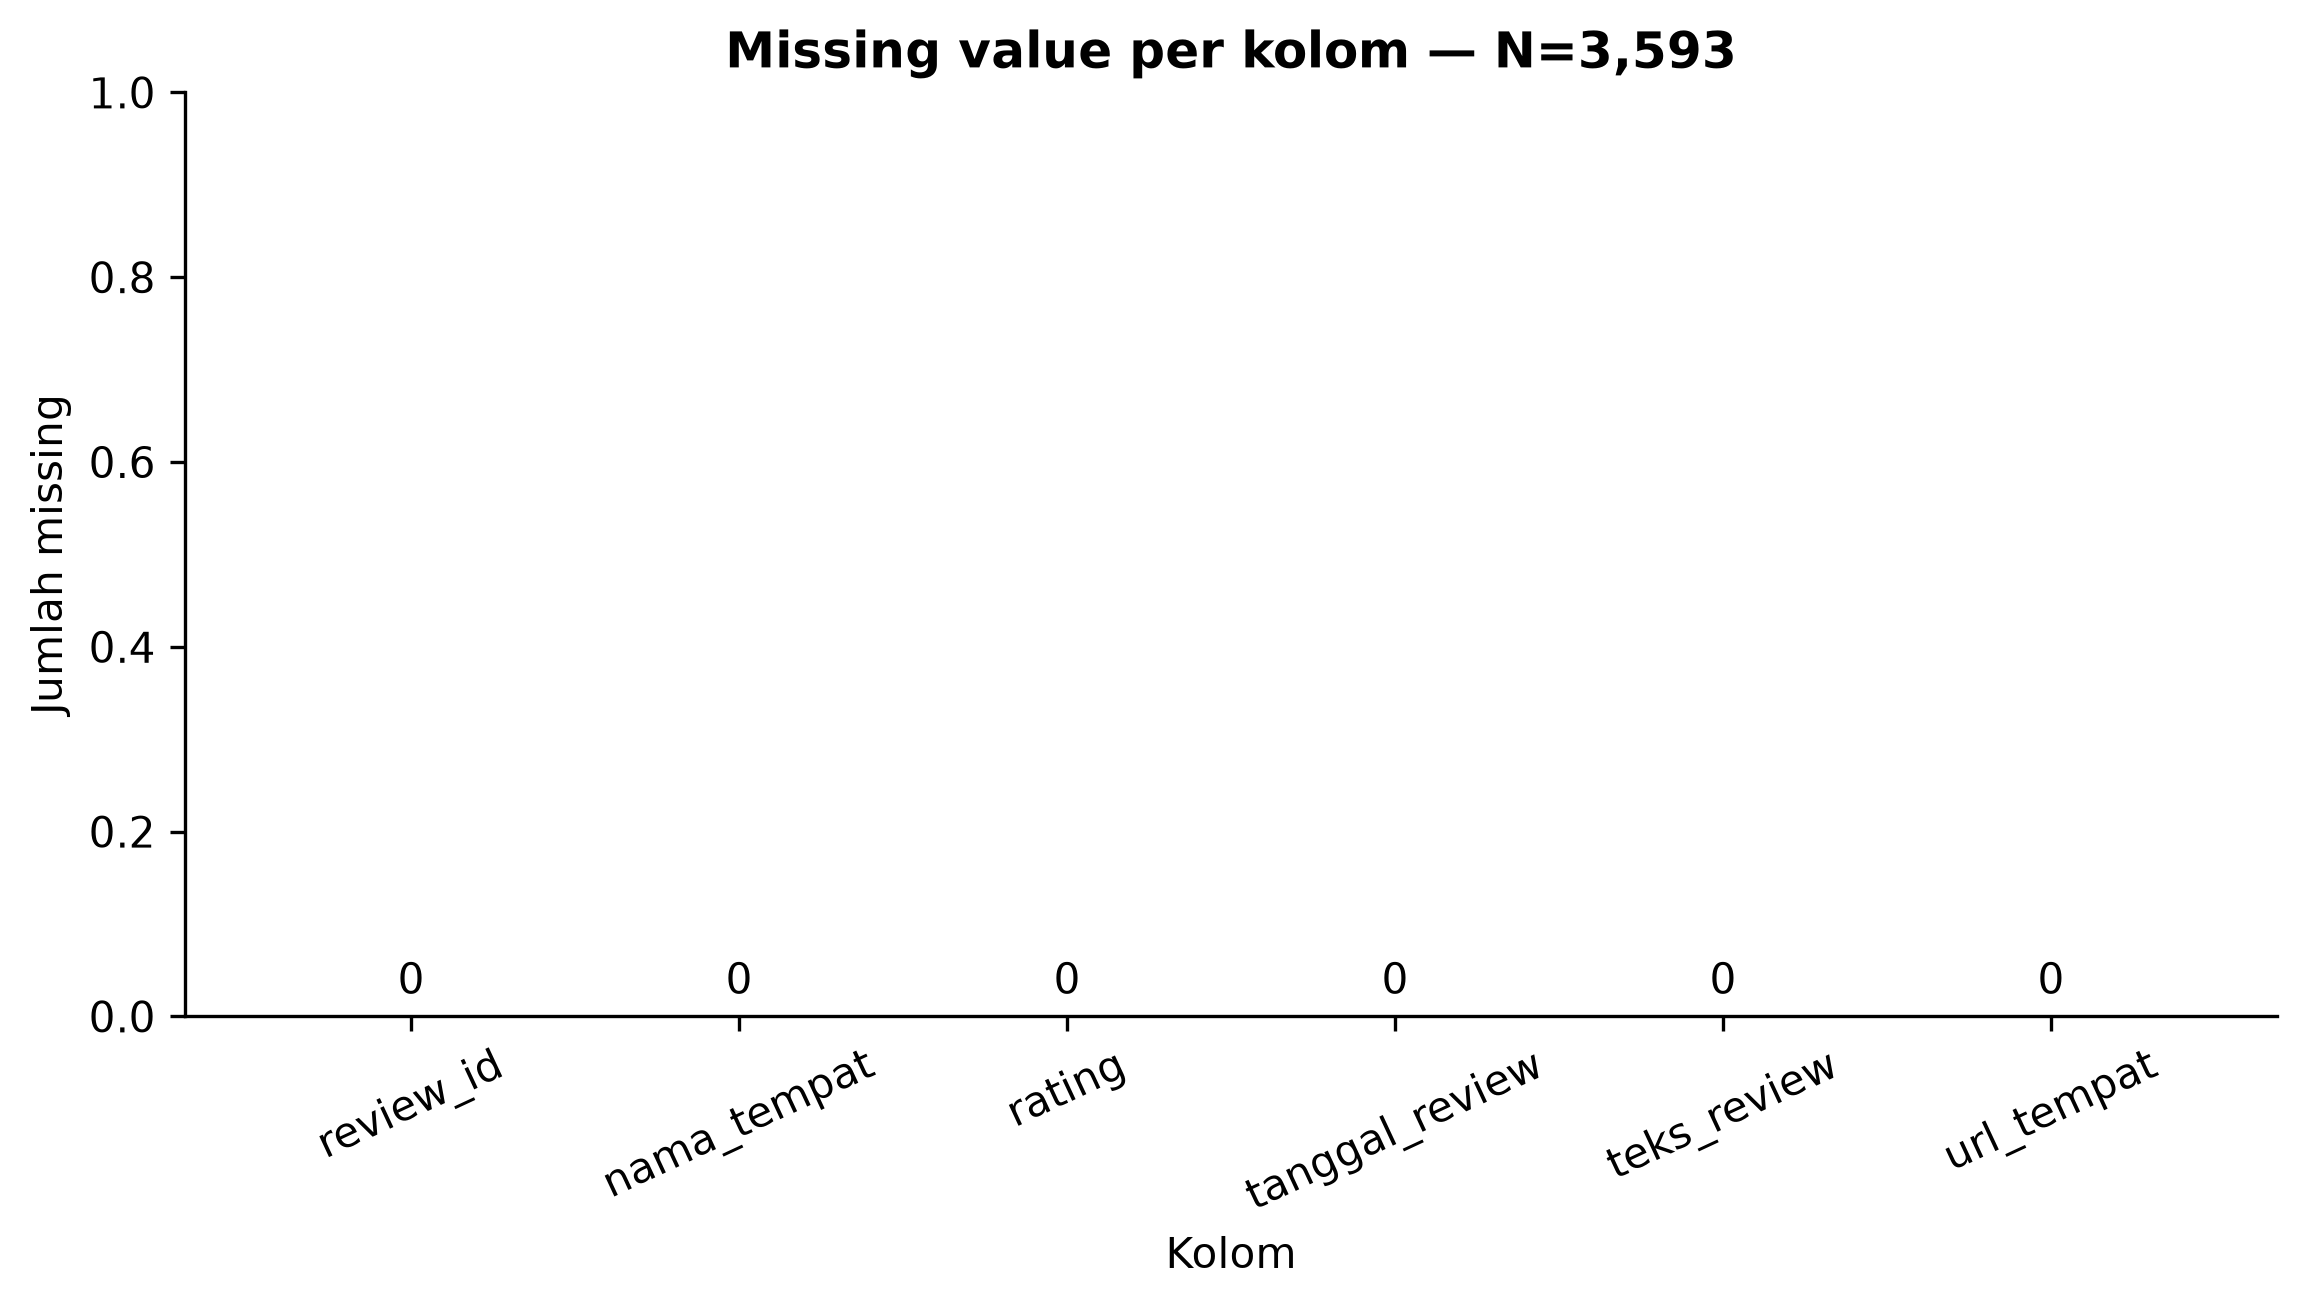

**Interpretasi dan implikasi.** Missing pada enam kolom: 0 sel. Rating invalid 0, tanggal invalid 0, tanggal setelah acuan 0, URL invalid 0. Teks simbol saja 11; pola relevansi rendah 0; indikasi email/telepon 0. Bahasa campuran terindikasi pada 164 review, slang pada 1120; 1019 review tanpa petunjuk Indonesia memerlukan pemeriksaan, bukan penghapusan. Tidak adanya missing tidak membuktikan bebas bias.

In [6]:
quality_rows = []
for column in REQUIRED_COLUMNS:
    values = raw[column]
    nulls = values.isna()
    empty = values.notna() & values.eq("")
    whitespace = values.notna() & values.ne("") & values.str.strip().eq("")
    quality_rows.append({
        "column": column, "null_count": int(nulls.sum()),
        "empty_string_count": int(empty.sum()), "whitespace_only_count": int(whitespace.sum()),
        "missing_total": int((nulls | empty | whitespace).sum()),
    })
quality = pd.DataFrame(quality_rows)
validity_flags = [
    "invalid_rating", "invalid_date", "future_date", "invalid_url", "is_symbol_only",
    "is_short_review", "is_potentially_irrelevant", "needs_privacy_review",
    "possible_mixed_language", "has_slang_hint", "language_needs_review",
    "inconsistent_place_name", "same_name_multiple_locations", "identity_needs_review",
]
validity = pd.DataFrame({
    "check": validity_flags, "flagged_rows": [int(audit[c].sum()) for c in validity_flags],
})
validity["flagged_pct"] = validity["flagged_rows"] / N * 100
display(quality, validity.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(quality["column"], quality["missing_total"], color=COLORS["main"])
ax.bar_label(bars, padding=3)
ax.set(title=f"Missing value per kolom — N={N:,}", xlabel="Kolom", ylabel="Jumlah missing")
ax.set_ylim(0, max(1, quality["missing_total"].max() * 1.2))
ax.tick_params(axis="x", rotation=25)
save_figure(fig, "missing_values.png")
show_interpretation("Kualitas data",
    f"Missing pada enam kolom: {int(quality['missing_total'].sum()):,} sel. "
    f"Rating invalid {int(audit['invalid_rating'].sum())}, tanggal invalid "
    f"{int(audit['invalid_date'].sum())}, tanggal setelah acuan {int(audit['future_date'].sum())}, "
    f"URL invalid {int(audit['invalid_url'].sum())}. "
    f"Teks simbol saja {int(audit['is_symbol_only'].sum())}; pola relevansi rendah "
    f"{int(audit['is_potentially_irrelevant'].sum())}; indikasi email/telepon "
    f"{int(audit['needs_privacy_review'].sum())}. Bahasa campuran terindikasi pada "
    f"{int(audit['possible_mixed_language'].sum())} review, slang pada "
    f"{int(audit['has_slang_hint'].sum())}; {int(audit['language_needs_review'].sum())} "
    "review tanpa petunjuk Indonesia memerlukan pemeriksaan, bukan penghapusan. "
    "Tidak adanya missing tidak membuktikan bebas bias.")


## 5. Duplicate & Data Validity Analysis

**Tujuan.** Membedakan pengulangan rekaman dan pengulangan ungkapan.

**Metode.** Hitung seluruh baris terlibat (keep=False) untuk ID, rekaman identik, exact text per kedai, normalisasi casefold/whitespace per kedai, dan teks lintas kedai. Kategori tumpang tindih sehingga tidak boleh dijumlahkan.

**Implikasi.** Teks sama dengan ID berbeda adalah potensi, bukan duplikasi tidak sah yang terkonfirmasi. Pengulangan ≤10 kata hanya kandidat ungkapan umum yang sah; batas ini bersifat heuristik.


,category,involved_rows,pct
0,ID review duplikat,0,0.00
1,Rekaman enam field identik,0,0.00
2,Teks exact pada kedai sama,61,1.70
3,Teks normalisasi pada kedai sama,94,2.62
4,Teks normalisasi lintas kedai,247,6.87


Salinan ekstra rekaman identik: 0
Baris ID konflik: 0
Kandidat ungkapan pendek berulang: 255


,review_id,nama_tempat,rating,word_count,teks_review
5,Ci9DQUlRQUNvZENodHljRjlvT25aVVoxVXlWbDlNVTNWcm...,Titik Awal Kopitiam Jatinangor (TIWAL),5,1,bagus
23,Ci9DQUlRQUNvZENodHljRjlvT2tvME9WUnBURzFJVEc5RF...,Titik Awal Kopitiam Jatinangor (TIWAL),5,1,mantapp
24,Ci9DQUlRQUNvZENodHljRjlvT25SV1JUQmpaakp1ZDFOM1...,Titik Awal Kopitiam Jatinangor (TIWAL),5,2,sangat baik
27,Ci9DQUlRQUNvZENodHljRjlvT2pVd2NIbFVNbE56TUhkdG...,Titik Awal Kopitiam Jatinangor (TIWAL),5,1,MANTAPP
29,Ci9DQUlRQUNvZENodHljRjlvT25oU1FsSlFTM2x0VTFoS1...,Titik Awal Kopitiam Jatinangor (TIWAL),5,1,Good
38,Ci9DQUlRQUNvZENodHljRjlvT205bVRYcENXV2R6YUdKNW...,Titik Awal Kopitiam Jatinangor (TIWAL),5,4,tempatnya oke dan nyaman
41,Ci9DQUlRQUNvZENodHljRjlvT20xa04wWkhUamxoTVRGM1...,Titik Awal Kopitiam Jatinangor (TIWAL),5,1,keren
44,Ci9DQUlRQUNvZENodHljRjlvT25ZM1NHcE9kWFpyZVRoWG...,Titik Awal Kopitiam Jatinangor (TIWAL),5,1,Comfy


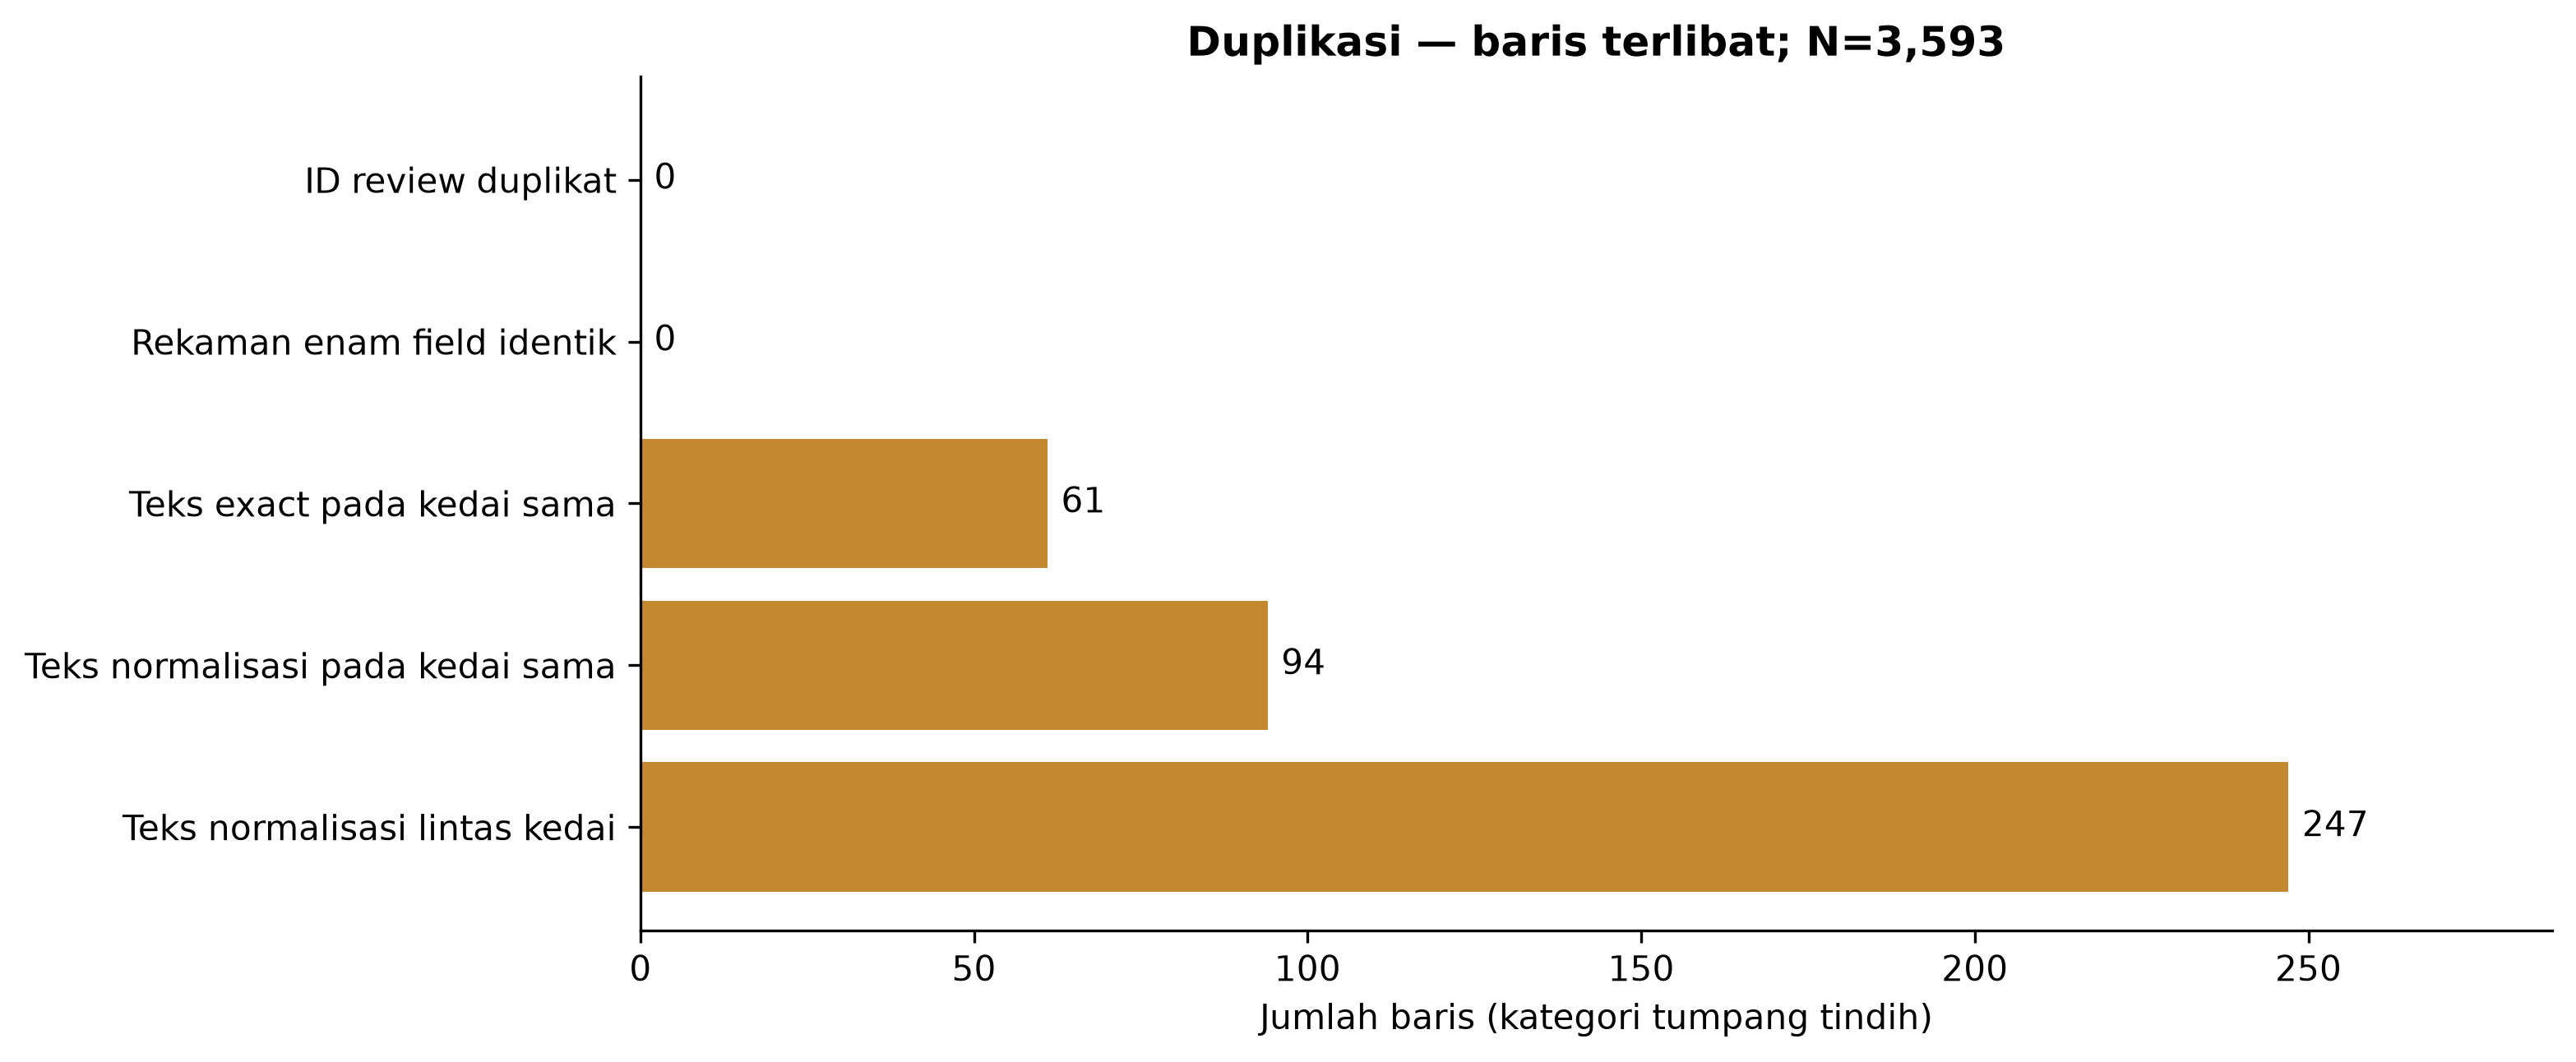

**Interpretasi dan implikasi.** ID duplikat melibatkan 0 baris; rekaman enam field identik 0 baris. Teks normalisasi berulang di kedai sama 94 baris; lintas kedai 247 baris. Sebanyak 255 baris kandidat merupakan ungkapan ≤10 kata yang mungkin sah. Semua dipertahankan. Deduplikasi memerlukan ID dan metadata; teks identik tidak cukup untuk membatalkan ulasan pelanggan berbeda.

In [7]:
duplicate_checks = {
    "ID review duplikat": "duplicate_review_id",
    "Rekaman enam field identik": "confirmed_record_duplicate",
    "Teks exact pada kedai sama": "exact_text_same_place",
    "Teks normalisasi pada kedai sama": "normalized_text_same_place",
    "Teks normalisasi lintas kedai": "text_across_places",
}
duplicates = pd.DataFrame([
    {"category": name, "involved_rows": int(audit[column].sum()),
     "pct": float(audit[column].mean() * 100)}
    for name, column in duplicate_checks.items()
])
display(duplicates.round(2))
print("Salinan ekstra rekaman identik:", int(audit["confirmed_duplicate_extra"].sum()))
print("Baris ID konflik:", int(audit["conflicting_review_id"].sum()))
print("Kandidat ungkapan pendek berulang:", int(audit["possible_legitimate_repetition"].sum()))
display(safe_examples(audit.loc[audit["potential_text_duplicate"]], 8))
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(duplicates["category"], duplicates["involved_rows"], color=COLORS["warn"])
ax.bar_label(bars, padding=4)
ax.set(title=f"Duplikasi — baris terlibat; N={N:,}", xlabel="Jumlah baris (kategori tumpang tindih)")
ax.invert_yaxis()
ax.margins(x=.16)
save_figure(fig, "duplicate_analysis.png")
show_interpretation("Duplikasi",
    f"ID duplikat melibatkan {int(audit['duplicate_review_id'].sum())} baris; "
    f"rekaman enam field identik {int(audit['confirmed_record_duplicate'].sum())} baris. "
    f"Teks normalisasi berulang di kedai sama {int(audit['normalized_text_same_place'].sum())} "
    f"baris; lintas kedai {int(audit['text_across_places'].sum())} baris. "
    f"Sebanyak {int(audit['possible_legitimate_repetition'].sum())} baris kandidat merupakan "
    "ungkapan ≤10 kata yang mungkin sah. Semua dipertahankan. Deduplikasi memerlukan "
    "ID dan metadata; teks identik tidak cukup untuk membatalkan ulasan pelanggan berbeda.")


## 6. Coffee Shop Distribution Analysis

**Tujuan.** Menilai representasi antarkedai dan kandidat masalah geografis.

**Metode.** Agregasi place key mencakup kontribusi, kualitas dasar, review pendek, duplikasi, rating, dan panjang teks. Kelompok <30, 30–49, 50–99, ≥100 hanya indikator awal.

**Geografi.** CSV tidak menyediakan alamat/koordinat administratif. Semua kedai tetap belum terverifikasi; petunjuk nama wilayah lain hanya memprioritaskan pemeriksaan, bukan menetapkan lokasi.

**Finalisasi geografis.** Kandidat koordinat dari URL daftar tempat lokal dan status per identitas dicatat dalam geographic_verification.csv pada bagian readiness. Tautan berdasarkan nama hanya menyiapkan kandidat bukti; belum memverifikasi place ID atau batas administratif. Sumber resmi yang diperiksa dirangkum dalam docs/research/data_provenance.md.


,nama_tempat,review_count,basic_quality_count,short_review_count,potential_duplicate_count,confirmed_duplicate_count,mean_rating,mean_word_count,median_word_count,mean_char_count,median_char_count,min_review_date,max_review_date,name_variant_count,geography_name_hint,identity_needs_review,contribution_pct,review_band,geography_status
0,Kopi Menak Rancaekek,151,151,7,1,0,4.84,17.19,15.0,113.03,100.0,2025-05-18 02:15:43.141000+00:00,2026-10-11 14:07:39.779000+00:00,1,True,False,4.20,≥100,unverified_no_administrative_evidence
1,Jabarano Coffee - Jaipong Jatinangor,137,137,17,5,0,4.83,15.96,11.0,103.44,67.0,2026-10-05 07:50:44.554000+00:00,2026-10-25 05:07:03.416000+00:00,1,False,False,3.81,≥100,unverified_no_administrative_evidence
2,Titik Awal Kopitiam Jatinangor (TIWAL),136,136,39,16,0,4.96,9.12,7.0,60.94,48.5,2026-09-18 17:05:35.992000+00:00,2026-10-22 12:44:16.114000+00:00,1,False,False,3.79,≥100,unverified_no_administrative_evidence
3,Alana Coffee & Eatery,136,136,29,6,0,4.92,12.91,8.0,84.43,50.5,2026-06-22 03:44:11.670000+00:00,2026-10-24 04:32:48.626000+00:00,1,False,False,3.79,≥100,unverified_no_administrative_evidence
4,Djoeroe Coffee,130,130,20,8,0,4.67,14.55,9.0,93.68,59.0,2025-08-17 10:51:50.876000+00:00,2026-10-22 03:24:01.552000+00:00,1,False,False,3.62,≥100,unverified_no_administrative_evidence
5,Tepi Kopi Jatinangor,128,127,21,4,0,4.89,14.61,11.0,94.03,68.5,2025-01-08 11:35:19.175000+00:00,2026-10-22 08:15:50.362000+00:00,1,False,False,3.56,≥100,unverified_no_administrative_evidence
6,Kopi Kenangan Jatos,127,127,37,8,0,4.68,9.52,6.0,62.17,42.0,2023-06-11 10:22:30.749000+00:00,2026-10-13 09:23:23.302000+00:00,1,False,False,3.53,≥100,unverified_no_administrative_evidence
7,Imah Kayu Jatinangor,124,124,15,6,0,4.74,16.64,9.0,110.15,62.5,2026-07-13 10:23:25.003000+00:00,2026-10-20 14:56:12.935000+00:00,1,False,False,3.45,≥100,unverified_no_administrative_evidence
8,Tekun.id Jatinagor,122,122,38,19,0,4.99,7.07,5.5,45.10,35.0,2026-05-22 07:32:33.045000+00:00,2026-10-23 08:34:55.536000+00:00,1,False,False,3.40,≥100,unverified_no_administrative_evidence
9,Meet Iokay,122,122,33,5,0,4.99,10.86,7.0,70.05,49.5,2024-11-18 09:41:23.982000+00:00,2026-07-23 02:35:50.311000+00:00,1,False,False,3.40,≥100,unverified_no_administrative_evidence


,review_count
count,40.00
mean,89.82
std,38.00
min,10.00
25%,73.75
50%,97.50
75%,113.75
max,151.00


,review_band,coffee_shops
0,<30,5
1,30–49,1
2,50–99,15
3,≥100,19


**10 kedai dengan sampel tersedikit**

,nama_tempat,review_count,contribution_pct,basic_quality_count
39,JC7 Cafe Jatinangor Center,10,0.28,10
38,Nora Coffee Jatinangor,11,0.31,11
37,BARRY'S Coffee & Eatery,13,0.36,13
36,Imahaing Coffee & Kitchen,15,0.42,15
35,Jatinangor coffee 2,17,0.47,16
34,Eiger Coffee Jatinangor,43,1.20,43
33,Jumpa Asa Coffee-nity & Eatery,53,1.48,53
32,Nomar Kopi Roastery Jatinangor - Cafe WFC & Ru...,59,1.64,59
31,Kopi Menak Roastery Jatinangor,61,1.70,61
30,"Aksata Coffee & Roastery, Jatinangor",67,1.86,66


**Petunjuk nama untuk verifikasi geografis (bukan geocoding)**

,nama_tempat,review_count,geography_status
0,Kopi Menak Rancaekek,151,unverified_no_administrative_evidence


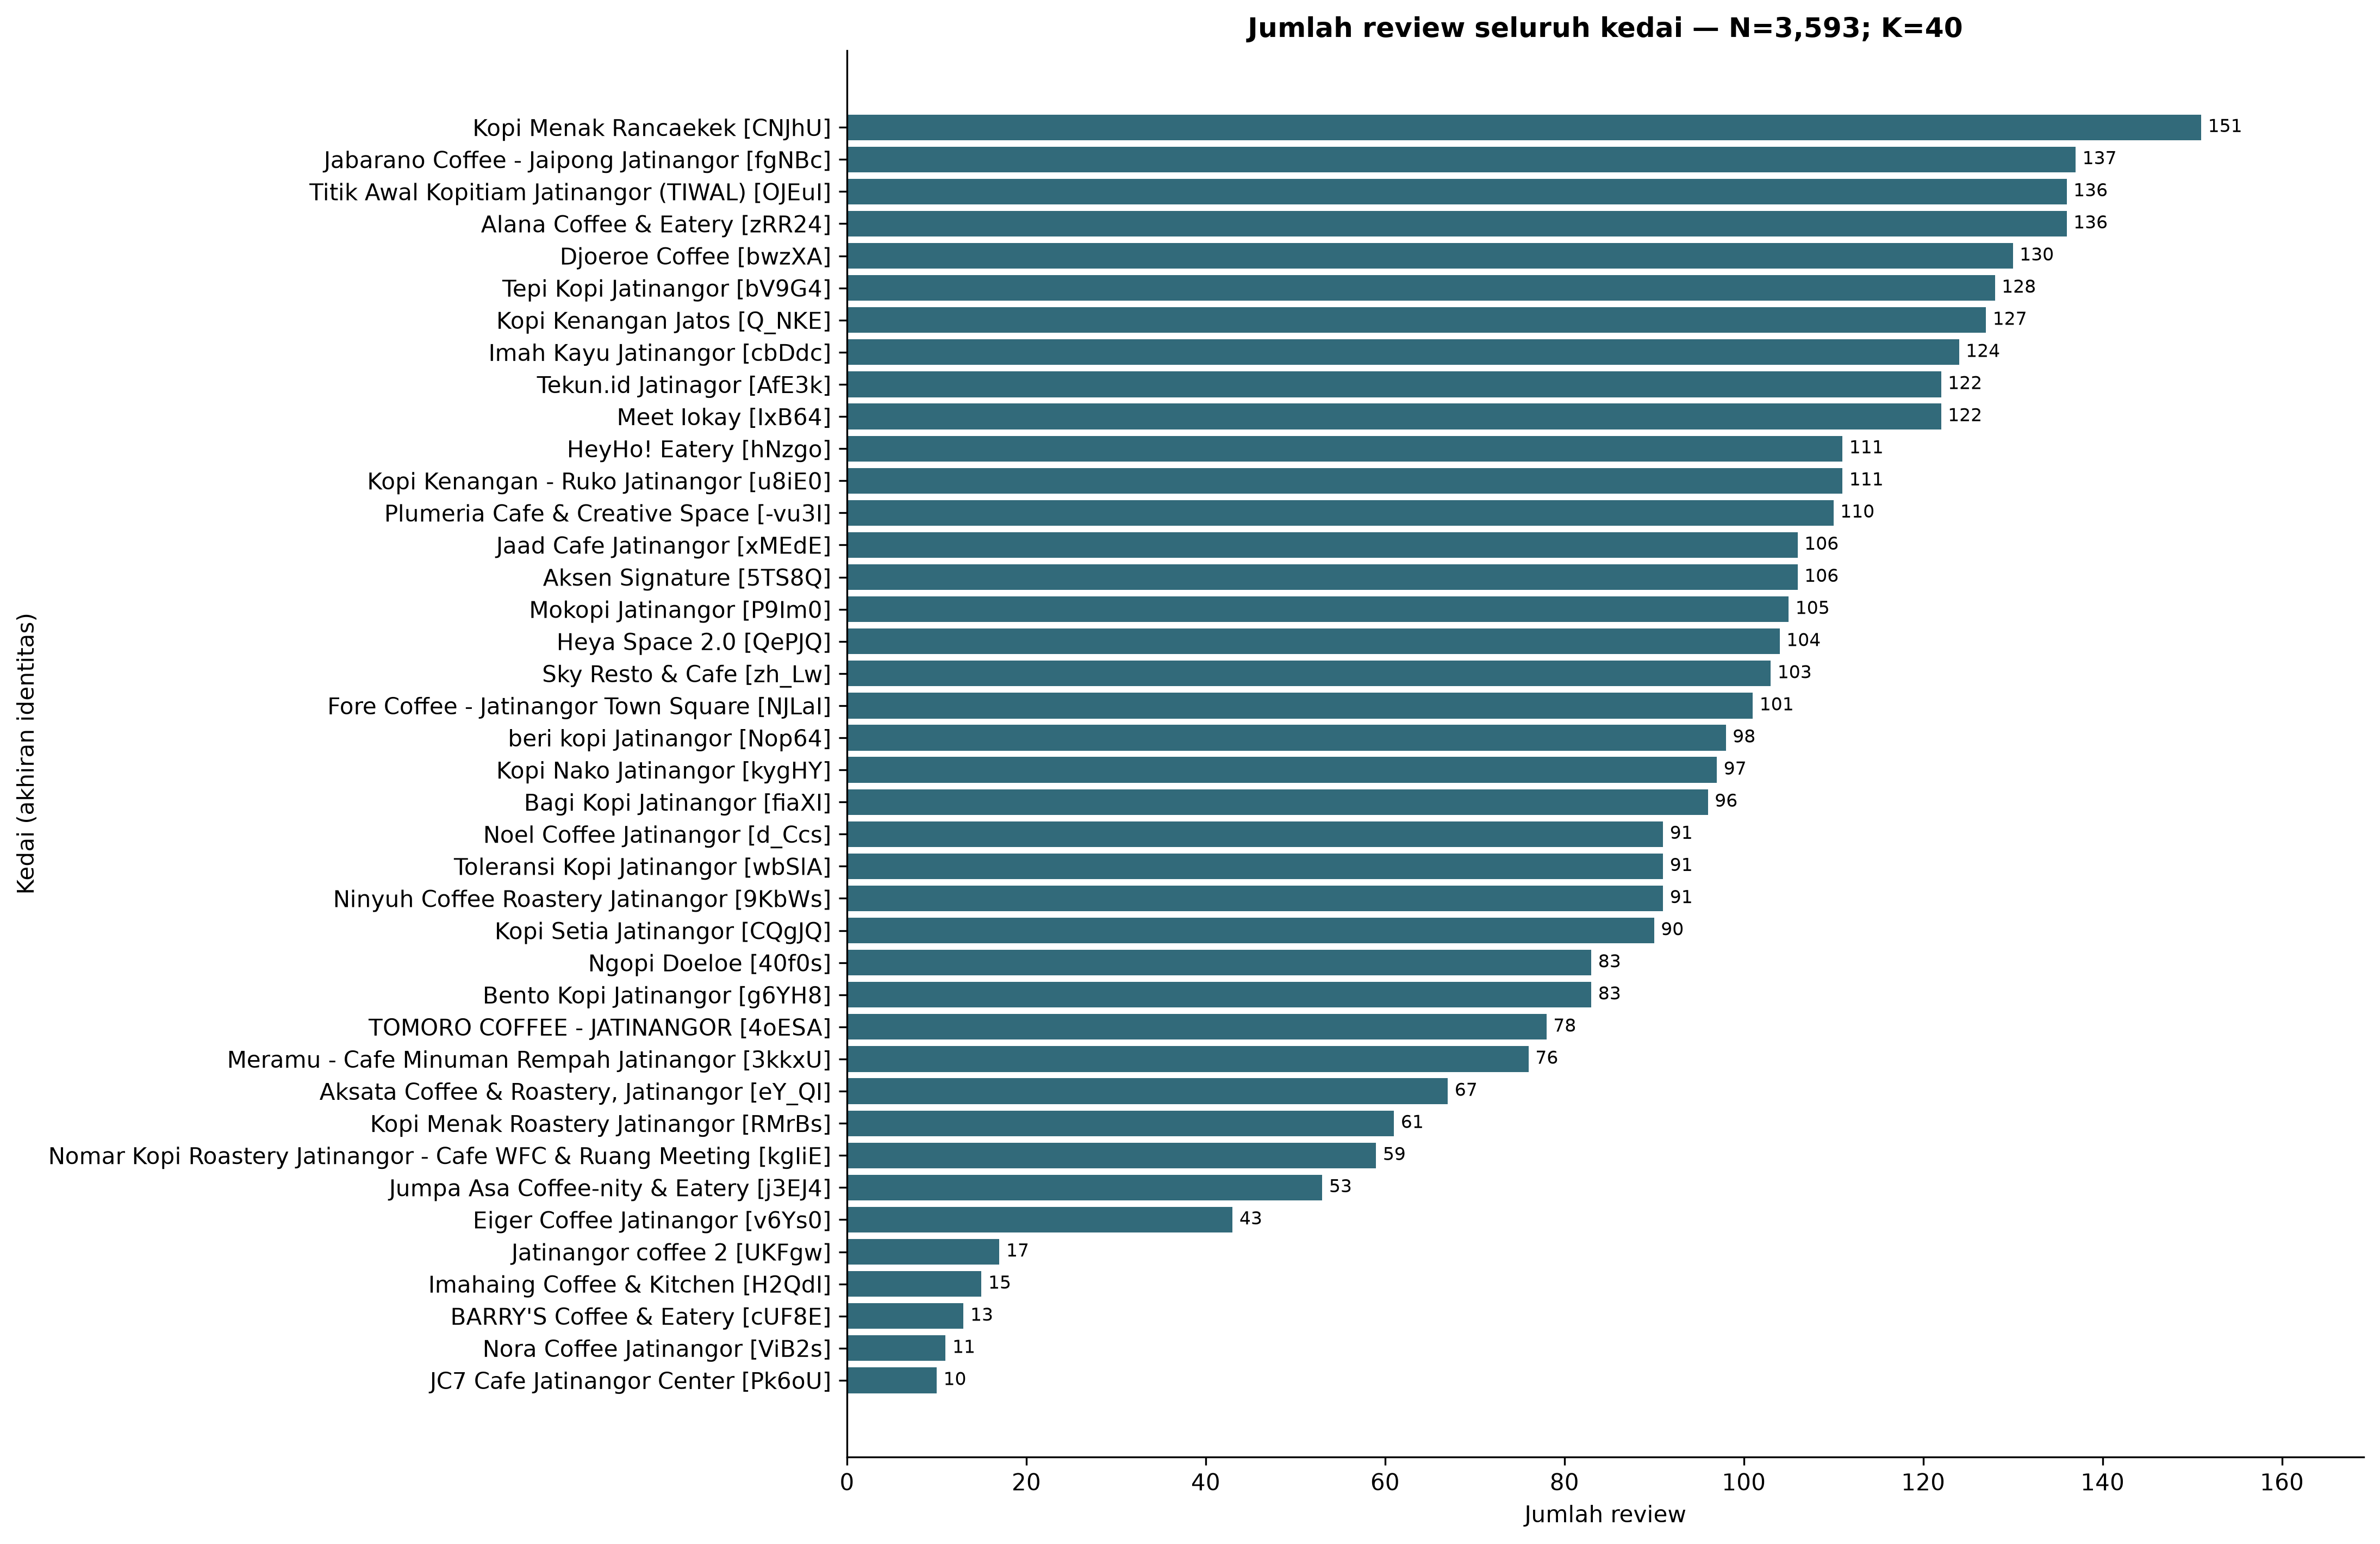

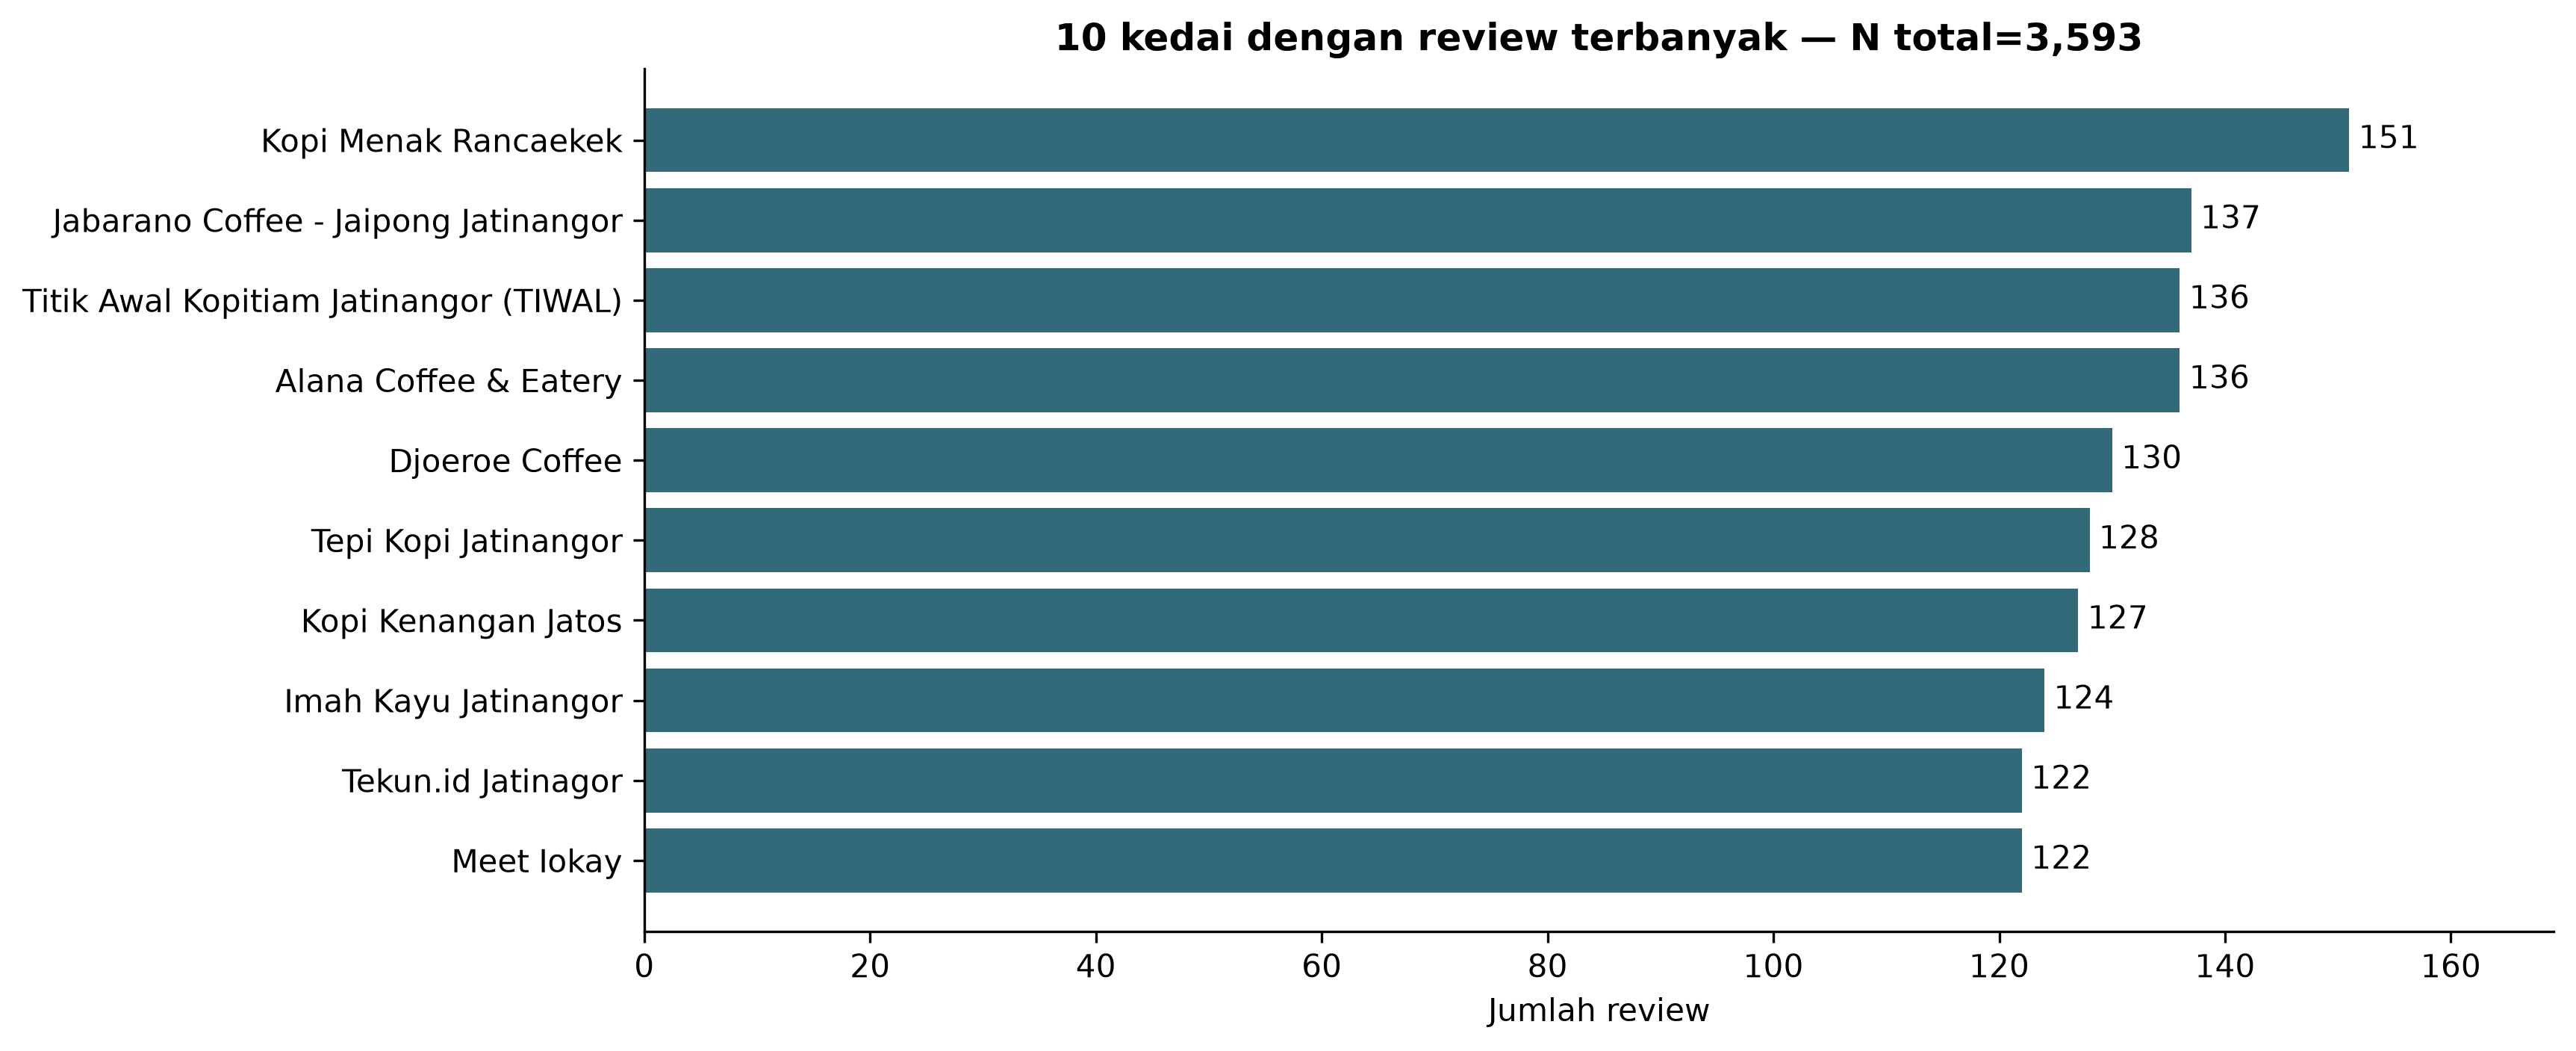

**Interpretasi dan implikasi.** Review per kedai berkisar 10–151; mean 89.83, median 97.50, SD sampel 38.00. Ada 5 kedai <30 review; kedai terbesar menyumbang 4.20% dataset. Petunjuk nama untuk prioritas geografis: Kopi Menak Rancaekek. Seluruh 40 identitas geografis tetap belum terverifikasi. Perbedaan sampel membatasi perbandingan kedai; jumlah besar tidak membuktikan keterwakilan pelanggan. Rancangan anotasi perlu mewakili kedai kecil.

In [8]:
count_stats = places["review_count"].describe().to_dict()
count_stats["std"] = float(places["review_count"].std(ddof=1)) if P > 1 else 0.0
place_bands = places["review_band"].value_counts(sort=False).rename_axis("review_band").reset_index(name="coffee_shops")
display(places.drop(columns=["url_tempat", "place_key"]).round(2))
display(pd.Series(count_stats, name="review_count").round(2).to_frame(), place_bands)
display(Markdown("**10 kedai dengan sampel tersedikit**"))
display(places.sort_values(["review_count", "nama_tempat"]).head(10)[
    ["nama_tempat", "review_count", "contribution_pct", "basic_quality_count"]
].round(2))
display(Markdown("**Petunjuk nama untuk verifikasi geografis (bukan geocoding)**"))
display(places.loc[places["geography_name_hint"], ["nama_tempat", "review_count", "geography_status"]])
fig, ax = plt.subplots(figsize=(12, max(8, P * .28)))
view = places.iloc[::-1]
labels = view["nama_tempat"] + " [" + view["place_key"].str[-5:] + "]"
bars = ax.barh(labels, view["review_count"], color=COLORS["main"])
ax.bar_label(bars, padding=3, fontsize=8)
ax.set(title=f"Jumlah review seluruh kedai — N={N:,}; K={P}", xlabel="Jumlah review", ylabel="Kedai (akhiran identitas)")
ax.margins(x=.12)
save_figure(fig, "review_distribution.png")
fig, ax = plt.subplots(figsize=(11, 5))
top = places.head(10).iloc[::-1]
bars = ax.barh(top["nama_tempat"], top["review_count"], color=COLORS["main"])
ax.bar_label(bars, padding=3)
ax.set(title=f"10 kedai dengan review terbanyak — N total={N:,}", xlabel="Jumlah review")
ax.margins(x=.12)
save_figure(fig, "top_coffee_shops.png")
small_count = int((places["review_count"] < MIN_PLACE_REVIEWS).sum())
geo_hint_names = places.loc[places["geography_name_hint"], "nama_tempat"].tolist()
show_interpretation("Distribusi kedai dan geografi",
    f"Review per kedai berkisar {int(count_stats['min'])}–{int(count_stats['max'])}; "
    f"mean {count_stats['mean']:.2f}, median {count_stats['50%']:.2f}, SD sampel "
    f"{count_stats['std']:.2f}. Ada {small_count} kedai <30 review; kedai terbesar "
    f"menyumbang {places['contribution_pct'].max():.2f}% dataset. "
    f"Petunjuk nama untuk prioritas geografis: {', '.join(geo_hint_names) or 'tidak ada'}. "
    f"Seluruh {P} identitas geografis tetap belum terverifikasi. Perbedaan sampel "
    "membatasi perbandingan kedai; jumlah besar tidak membuktikan keterwakilan pelanggan. "
    "Rancangan anotasi perlu mewakili kedai kecil.")


## 7. Text Characteristics Analysis

**Tujuan.** Mengukur kekayaan konteks untuk anotasi aspek.

**Metode.** Karakter dihitung dari teks asli. Kata adalah token alfanumerik Unicode, tanda baca/emoji tidak dihitung. Tampilkan P25/P50/P75/P90/P95, rentang <4/4–10/>10 kata, serta boxplot per kedai. Review pendek tidak dihapus.

**Hasil.** Histogram memakai seluruh rentang panjang; outlier hanya disembunyikan pada gambar boxplot demi keterbacaan, tetap masuk semua statistik.


,char_count,word_count
count,3593.00,3593.00
mean,96.64,15.09
std,142.68,22.66
min,1.00,0.00
25%,26.00,4.00
50%,56.00,9.00
75%,115.00,18.00
90%,213.00,33.80
95%,308.40,48.00
max,2681.00,411.00


,word_band,reviews,pct
0,<4 kata,778,21.65
1,4–10 kata,1298,36.13
2,>10 kata,1517,42.22


**Contoh review sangat pendek**

,review_id,nama_tempat,rating,word_count,teks_review
389,ChdDSUhNMG9nS0VJQ0FnSURuNU5PdHZnRRAB,Jatinangor coffee 2,5,0,👍👍👍👍👍
1853,Ci9DQUlRQUNvZENodHljRjlvT21KVFpVRXpYM0oxZFdOSE...,TOMORO COFFEE - JATINANGOR,5,0,❤️
2351,ChZDSUhNMG9nS0VJQ0FnSURfeWJtYWV3EAE,Tepi Kopi Jatinangor,5,0,👍🏻👍🏻👍🏻
2363,Ci9DQUlRQUNvZENodHljRjlvT2xwV1VUZFBRa2hEYVRkUG...,"Aksata Coffee & Roastery, Jatinangor",5,0,👍🏾
2669,ChZDSUhNMG9nS0VJQ0FnSURual9ER2NREAE,Meramu - Cafe Minuman Rempah Jatinangor,5,0,👍


**Contoh review panjang — dipotong hanya pada tampilan**

,review_id,nama_tempat,rating,word_count,teks_review
1382,Ci9DQUlRQUNvZENodHljRjlvT20xQmJsRmxjMlpUWVhCS1...,Plumeria Cafe & Creative Space,3,411,"Halo, Plumeria. Sebelumnya maaf saya memberika..."
2086,ChZDSUhNMG9nS0VJQ0FnSUREeXNqVkV3EAE,HeyHo! Eatery,1,385,Feedbacknya agak panjang maaf ya\nAku reservas...
2434,ChZDSUhNMG9nS0VJQ0FnSUNUd1B2WmFBEAE,"Aksata Coffee & Roastery, Jatinangor",5,327,Aku ngekos di tempat yang nempel banget sama c...


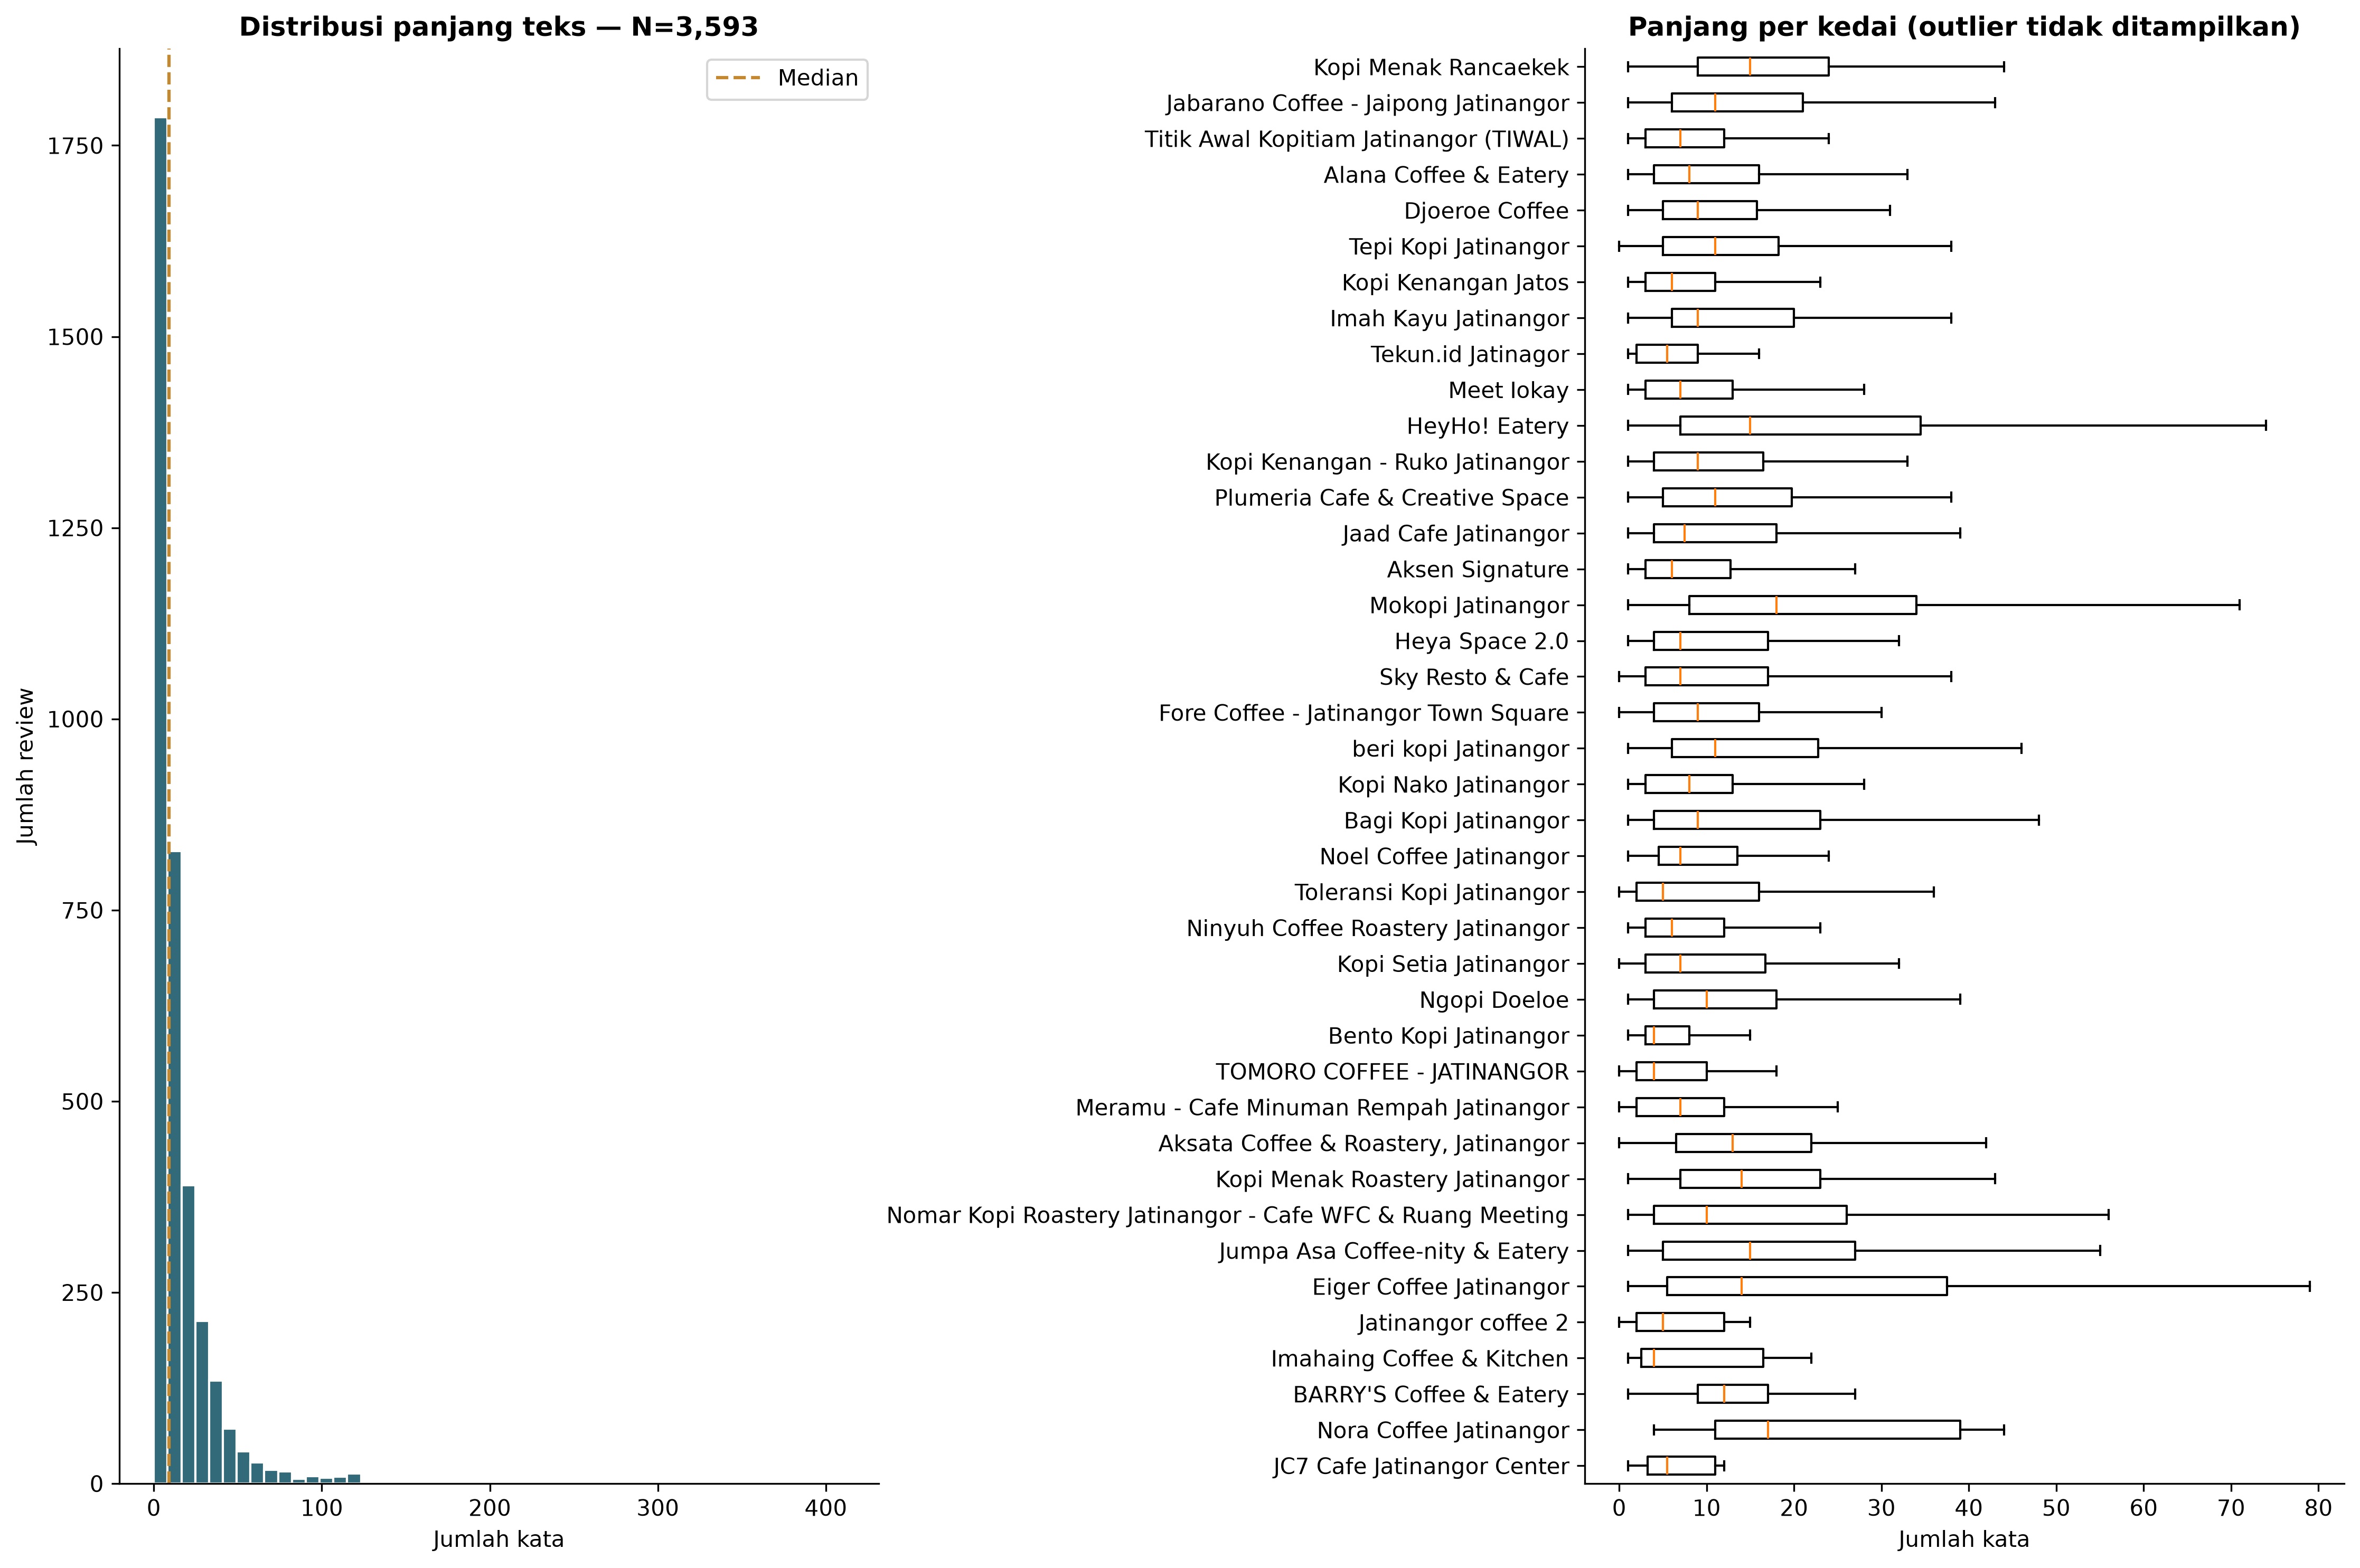

**Interpretasi dan implikasi.** Mean panjang 15.09 kata (96.64 karakter); median 9.0 kata. Rentang 0–411 kata; SD 22.66. Review <4 kata: 778 (21.65%). P90=33.8; P95=48.0. Anotasi harus mencakup review pendek/panjang; panjang tidak menentukan validitas atau jumlah aspek. Teks asli tidak diubah.

In [9]:
text_stats = audit[["char_count", "word_count"]].describe(percentiles=[.25, .5, .75, .9, .95]).round(2)
word_bins = pd.cut(audit["word_count"], [-1, 3, 10, np.inf], labels=["<4 kata", "4–10 kata", ">10 kata"])
length_bands = word_bins.value_counts(sort=False).rename_axis("word_band").reset_index(name="reviews")
length_bands["pct"] = length_bands["reviews"] / N * 100
display(text_stats, length_bands.round(2))
display(Markdown("**Contoh review sangat pendek**"))
display(safe_examples(audit.sort_values(["word_count", "source_row_number"]), 5))
display(Markdown("**Contoh review panjang — dipotong hanya pada tampilan**"))
display(safe_examples(audit.sort_values(["word_count", "source_row_number"], ascending=[False, True]), 3))
fig, axes = plt.subplots(1, 2, figsize=(15, max(10, P * .24)))
axes[0].hist(audit["word_count"], bins=50, color=COLORS["main"], edgecolor="white")
axes[0].axvline(audit["word_count"].median(), color=COLORS["warn"], linestyle="--", label="Median")
axes[0].set(title=f"Distribusi panjang teks — N={N:,}", xlabel="Jumlah kata", ylabel="Jumlah review")
axes[0].legend()
ordered_keys = places.iloc[::-1]["place_key"].tolist()
axes[1].boxplot(
    [audit.loc[audit["place_key"].eq(key), "word_count"].to_numpy() for key in ordered_keys],
    orientation="horizontal", tick_labels=places.iloc[::-1]["nama_tempat"].tolist(), showfliers=False,
)
axes[1].set(title="Panjang per kedai (outlier tidak ditampilkan)", xlabel="Jumlah kata")
fig.tight_layout()
save_figure(fig, "review_length_distribution.png")
show_interpretation("Karakteristik teks",
    f"Mean panjang {audit['word_count'].mean():.2f} kata ({audit['char_count'].mean():.2f} karakter); "
    f"median {audit['word_count'].median():.1f} kata. Rentang {int(audit['word_count'].min())}–"
    f"{int(audit['word_count'].max())} kata; SD {audit['word_count'].std():.2f}. "
    f"Review <4 kata: {int(word_bins.eq('<4 kata').sum())} "
    f"({word_bins.eq('<4 kata').mean()*100:.2f}%). P90={audit['word_count'].quantile(.9):.1f}; "
    f"P95={audit['word_count'].quantile(.95):.1f}. "
    "Anotasi harus mencakup review pendek/panjang; panjang tidak menentukan validitas "
    "atau jumlah aspek. Teks asli tidak diubah.")


## 8. Rating Distribution Analysis

**Tujuan.** Mengukur dominasi rating serta asosiasi deskriptif dengan panjang teks.

**Metode.** Hitung setiap rating 1–5, per kedai, kelompok tinggi 4–5/rendah 1–2, serta tabel panjang teks per rating. Persentase memakai seluruh N; invalid dihitung terpisah. Korelasi Spearman dihitung melalui korelasi antar rank.

**Implikasi.** Rating adalah metadata sampel. Bintang 5 tetap dapat mengandung keluhan; tidak dibuat label positif/netral/negatif pada tahap ini.


,rating,reviews,pct_of_all_reviews
0,1,189,5.26
1,2,53,1.48
2,3,105,2.92
3,4,175,4.87
4,5,3071,85.47


,place_key,nama_tempat,1,2,3,4,5
0,place_id:ChIJb1RNRrDFaC4RvTc2SNCNJhU,Kopi Menak Rancaekek,4,0,2,4,141
1,place_id:ChIJUw0tP3PFaC4RldVvxGfgNBc,Jabarano Coffee - Jaipong Jatinangor,3,1,3,2,128
2,place_id:ChIJA3DPaQTFaC4Rovkr-VOJEuI,Titik Awal Kopitiam Jatinangor (TIWAL),0,0,2,2,132
3,place_id:ChIJj33agDrFaC4RnSeMcgzRR24,Alana Coffee & Eatery,0,1,1,6,128
4,place_id:ChIJ55_Cj1bFaC4R7GBBwGbwzXA,Djoeroe Coffee,9,2,0,1,118
5,place_id:ChIJg8OgGdTFaC4RF_CwzybV9G4,Tepi Kopi Jatinangor,2,0,2,2,122
6,place_id:ChIJNZfmYuHFaC4RR7-4TNQ_NKE,Kopi Kenangan Jatos,8,1,1,4,113
7,place_id:ChIJG4zVdlTFaC4RoV1evBcbDdc,Imah Kayu Jatinangor,6,0,2,4,112
8,place_id:ChIJmwVyWLfFaC4Rd1bXnsAfE3k,Tekun.id Jatinagor,0,0,0,1,121
9,place_id:ChIJyWX2AADFaC4RVjgcebIxB64,Meet Iokay,0,0,0,1,121


,reviews,mean_words,median_words
rating_numeric,,,
1,189,31.69,19.0
2,53,50.66,44.0
3,105,34.94,23.0
4,175,26.42,17.0
5,3071,12.13,8.0


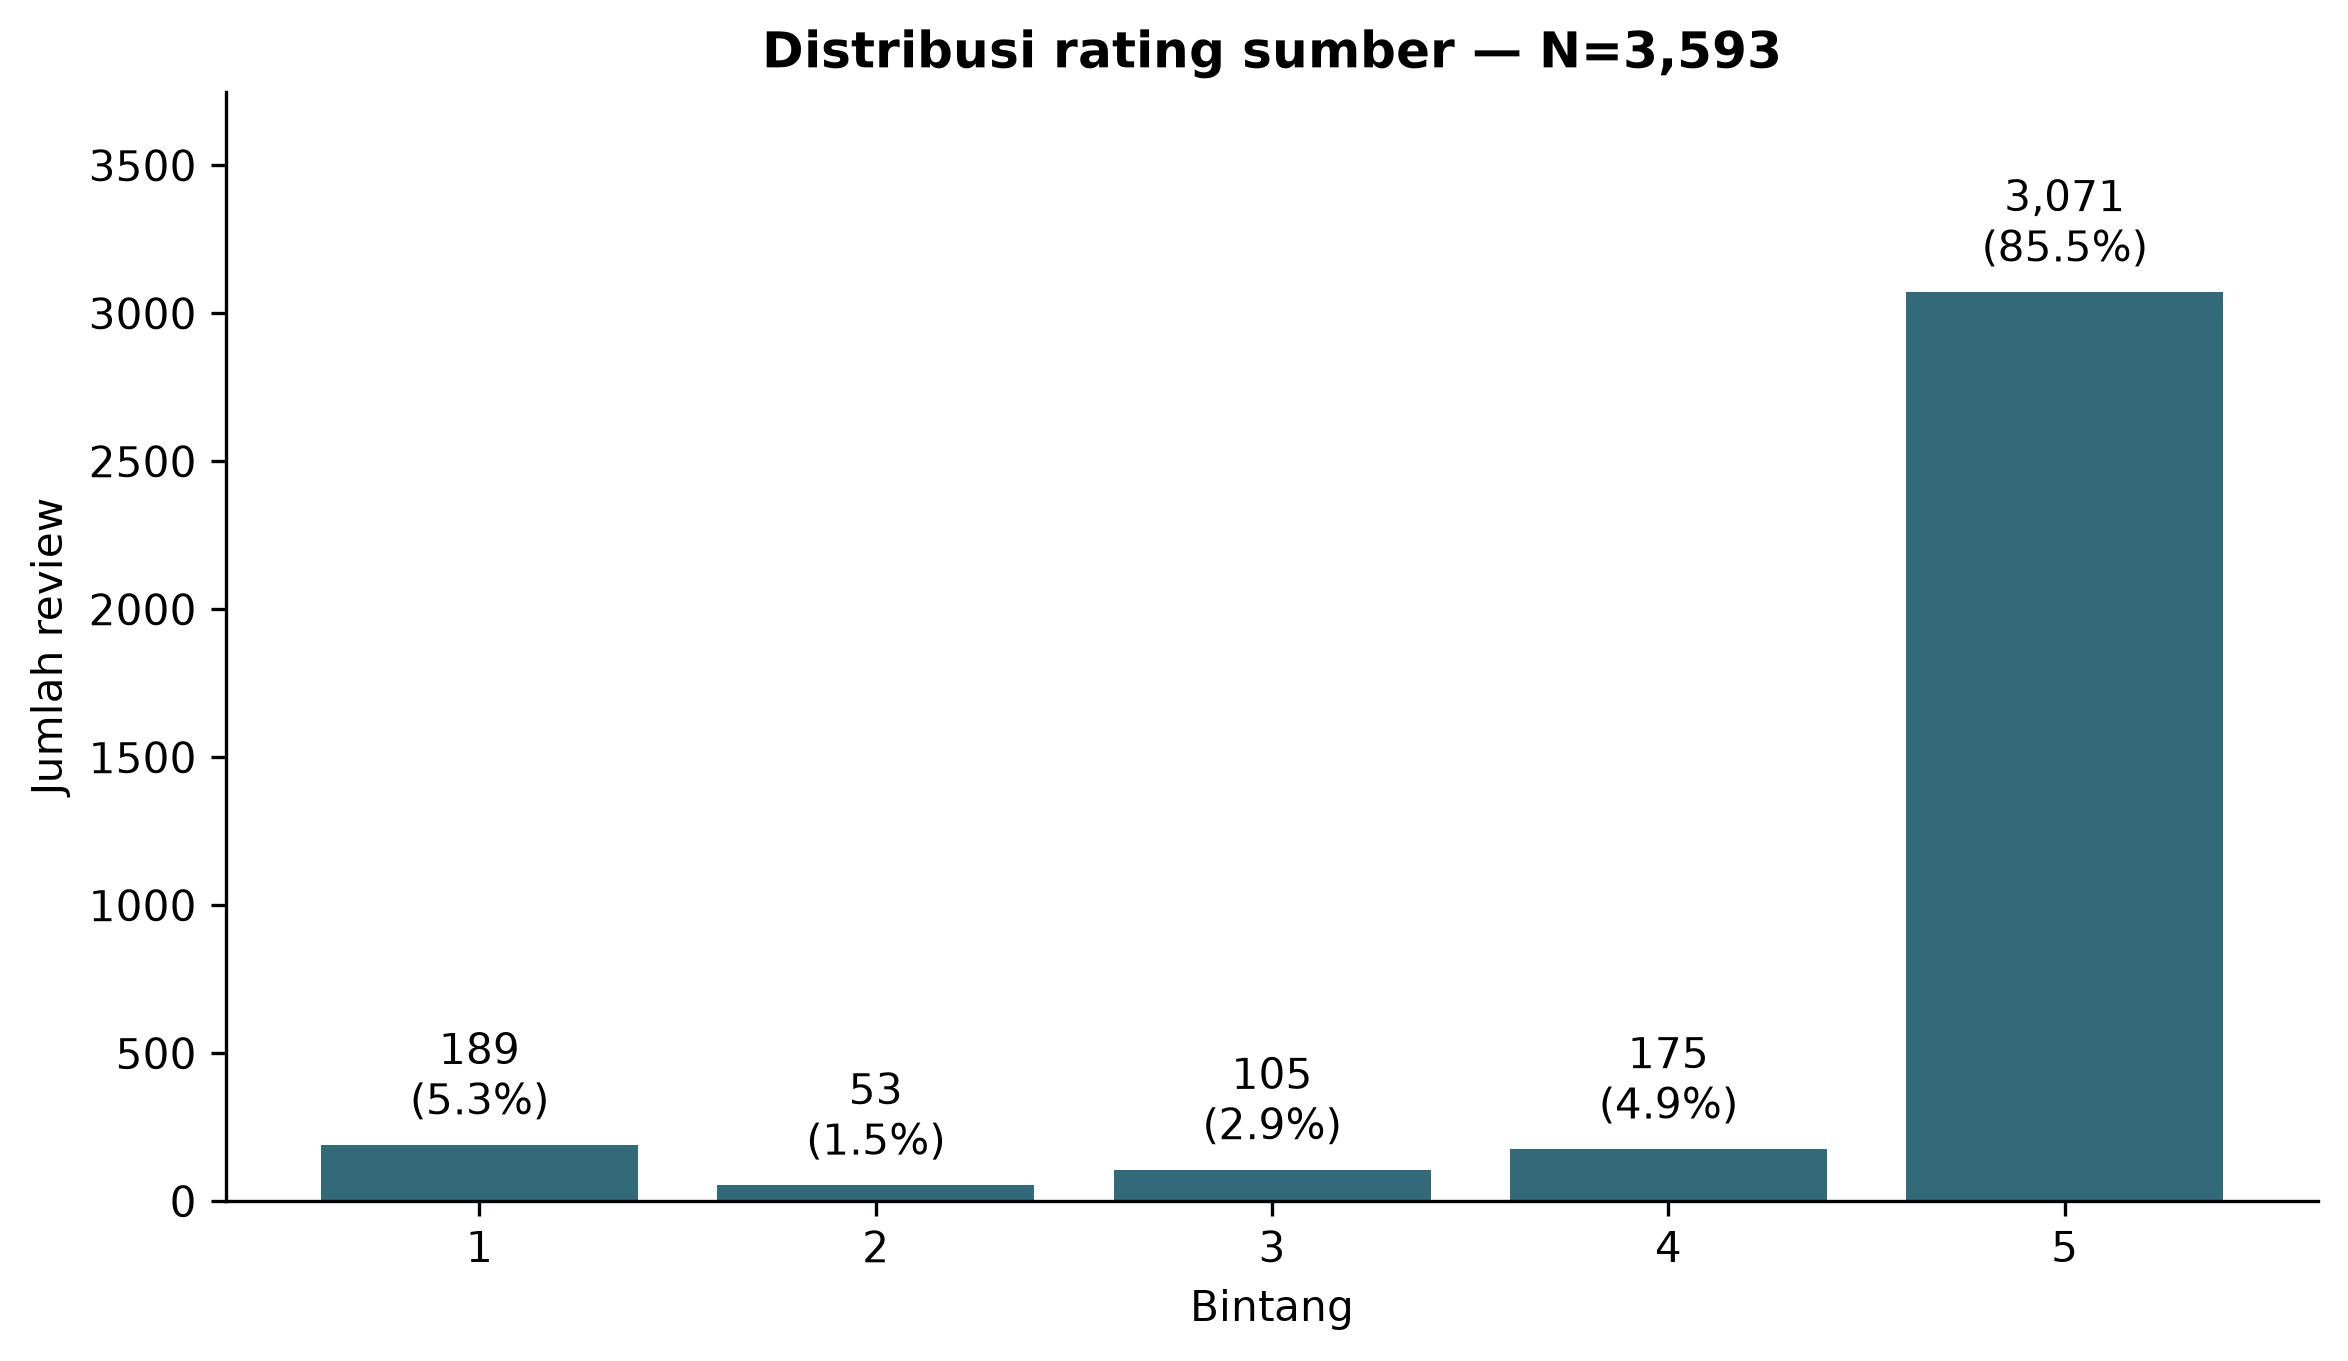

**Interpretasi dan implikasi.** Bintang lima 3,071 (85.47%). Rating tinggi 4–5: 90.34%; rendah 1–2: 6.74%. Mean rating valid 4.64, median 5.0. Korelasi rank rating–panjang -0.286, bersifat deskriptif dan tidak kausal. Dominasi rating tinggi berpotensi membatasi variasi pengalaman dalam sampel. Distribusi sentimen aspek baru diketahui setelah anotasi.

In [10]:
valid_ratings = audit.loc[~audit["invalid_rating"], "rating_numeric"]
rating_counts = valid_ratings.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0).sort_index()
rating_table = rating_counts.rename_axis("rating").reset_index(name="reviews")
rating_table["pct_of_all_reviews"] = rating_table["reviews"] / N * 100
rating_by_place = pd.crosstab(
    audit.loc[~audit["invalid_rating"], "place_key"], valid_ratings
).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
rating_by_place = places[["place_key", "nama_tempat"]].merge(rating_by_place, on="place_key", how="left").fillna(0)
rating_length = audit.loc[~audit["invalid_rating"]].groupby("rating_numeric").agg(
    reviews=("word_count", "size"), mean_words=("word_count", "mean"), median_words=("word_count", "median"),
)
high_pct = float(audit["rating_numeric"].isin([4, 5]).mean() * 100)
low_pct = float(audit["rating_numeric"].isin([1, 2]).mean() * 100)
rating_word_rho = float(valid_ratings.rank().corr(audit.loc[valid_ratings.index, "word_count"].rank()))
display(rating_table.round(2), rating_by_place, rating_length.round(2))
fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar([str(i) for i in range(1, 6)], rating_counts, color=COLORS["main"])
ax.bar_label(bars, labels=[f"{n:,}\n({n/N*100:.1f}%)" for n in rating_counts], padding=4)
ax.set(title=f"Distribusi rating sumber — N={N:,}", xlabel="Bintang", ylabel="Jumlah review")
ax.set_ylim(0, max(1, rating_counts.max() * 1.22))
save_figure(fig, "rating_distribution.png")
show_interpretation("Rating dan bias sampel",
    f"Bintang lima {int(rating_counts.loc[5]):,} ({rating_counts.loc[5]/N*100:.2f}%). "
    f"Rating tinggi 4–5: {high_pct:.2f}%; rendah 1–2: {low_pct:.2f}%. "
    f"Mean rating valid {valid_ratings.mean():.2f}, median {valid_ratings.median():.1f}. "
    f"Korelasi rank rating–panjang {rating_word_rho:.3f}, bersifat deskriptif dan tidak kausal. "
    "Dominasi rating tinggi berpotensi membatasi variasi pengalaman dalam sampel. "
    "Distribusi sentimen aspek baru diketahui setelah anotasi.")


## 9. Preliminary Aspect Coverage Exploration

**Tujuan.** Memperkirakan ketersediaan teks untuk enam kandidat aspek dan prioritas sampling anotasi.

**Metode.** Kamus eksplisit ditampilkan; pencocokan case-insensitive memakai boundary kata Unicode dan whitespace fleksibel untuk frasa. Satu review dapat cocok dengan beberapa aspek; frekuensi tiap aspek adalah jumlah review yang memiliki ≥1 keyword, bukan jumlah token. Persentase kedai dibagi semua review kedai.

**Keterbatasan.** Keyword matching bukan ground truth aspect extraction. Tidak terdeteksi bukan berarti tidak disebutkan. “Meja” dan “toilet” dapat berkaitan dengan beberapa aspek tergantung konteks; belum ada evaluasi recall/precision. Frekuensi bukan kepuasan atau sentimen.


,aspect,keywords
0,Product Quality,"kopi, kopinya, coffee, espresso, latte, cappuc..."
1,Service,"pelayanan, pelayanannya, layanan, service, sta..."
2,Price & Value,"harga, harganya, price, murah, mahal, terjangk..."
3,Ambience,"suasana, suasananya, nyaman, nyamannya, cozy, ..."
4,Facilities,"wifi, wi fi, wi-fi, internet, parkir, parkirny..."
5,Cleanliness,"bersih, bersihnya, kebersihan, kebersihannya, ..."


,aspect,review_mentions,coverage_pct
0,Product Quality,1452,40.41
1,Service,889,24.74
2,Price & Value,430,11.97
3,Ambience,1343,37.38
4,Facilities,277,7.71
5,Cleanliness,175,4.87


,Product Quality,Service,Price & Value,Ambience,Facilities,Cleanliness
Kopi Menak Rancaekek,69.5,34.4,15.9,59.6,2.6,10.6
Jabarano Coffee - Jaipong Jatinangor,41.6,35.0,6.6,40.1,5.1,5.8
Titik Awal Kopitiam Jatinangor (TIWAL),38.2,8.8,8.1,40.4,1.5,1.5
Alana Coffee & Eatery,33.8,22.1,17.6,49.3,8.1,7.4
Djoeroe Coffee,46.9,26.2,4.6,31.5,6.9,3.1
Tepi Kopi Jatinangor,46.1,11.7,14.8,57.8,7.0,3.1
Kopi Kenangan Jatos,32.3,49.6,3.9,25.2,1.6,7.9
Imah Kayu Jatinangor,68.5,25.0,21.0,49.2,4.8,8.9
Tekun.id Jatinagor,40.2,25.4,14.8,15.6,0.8,0.8
Meet Iokay,34.4,9.8,23.0,42.6,2.5,0.8


Tanpa keyword: 1052 | ≥2 aspek terindikasi: 1309


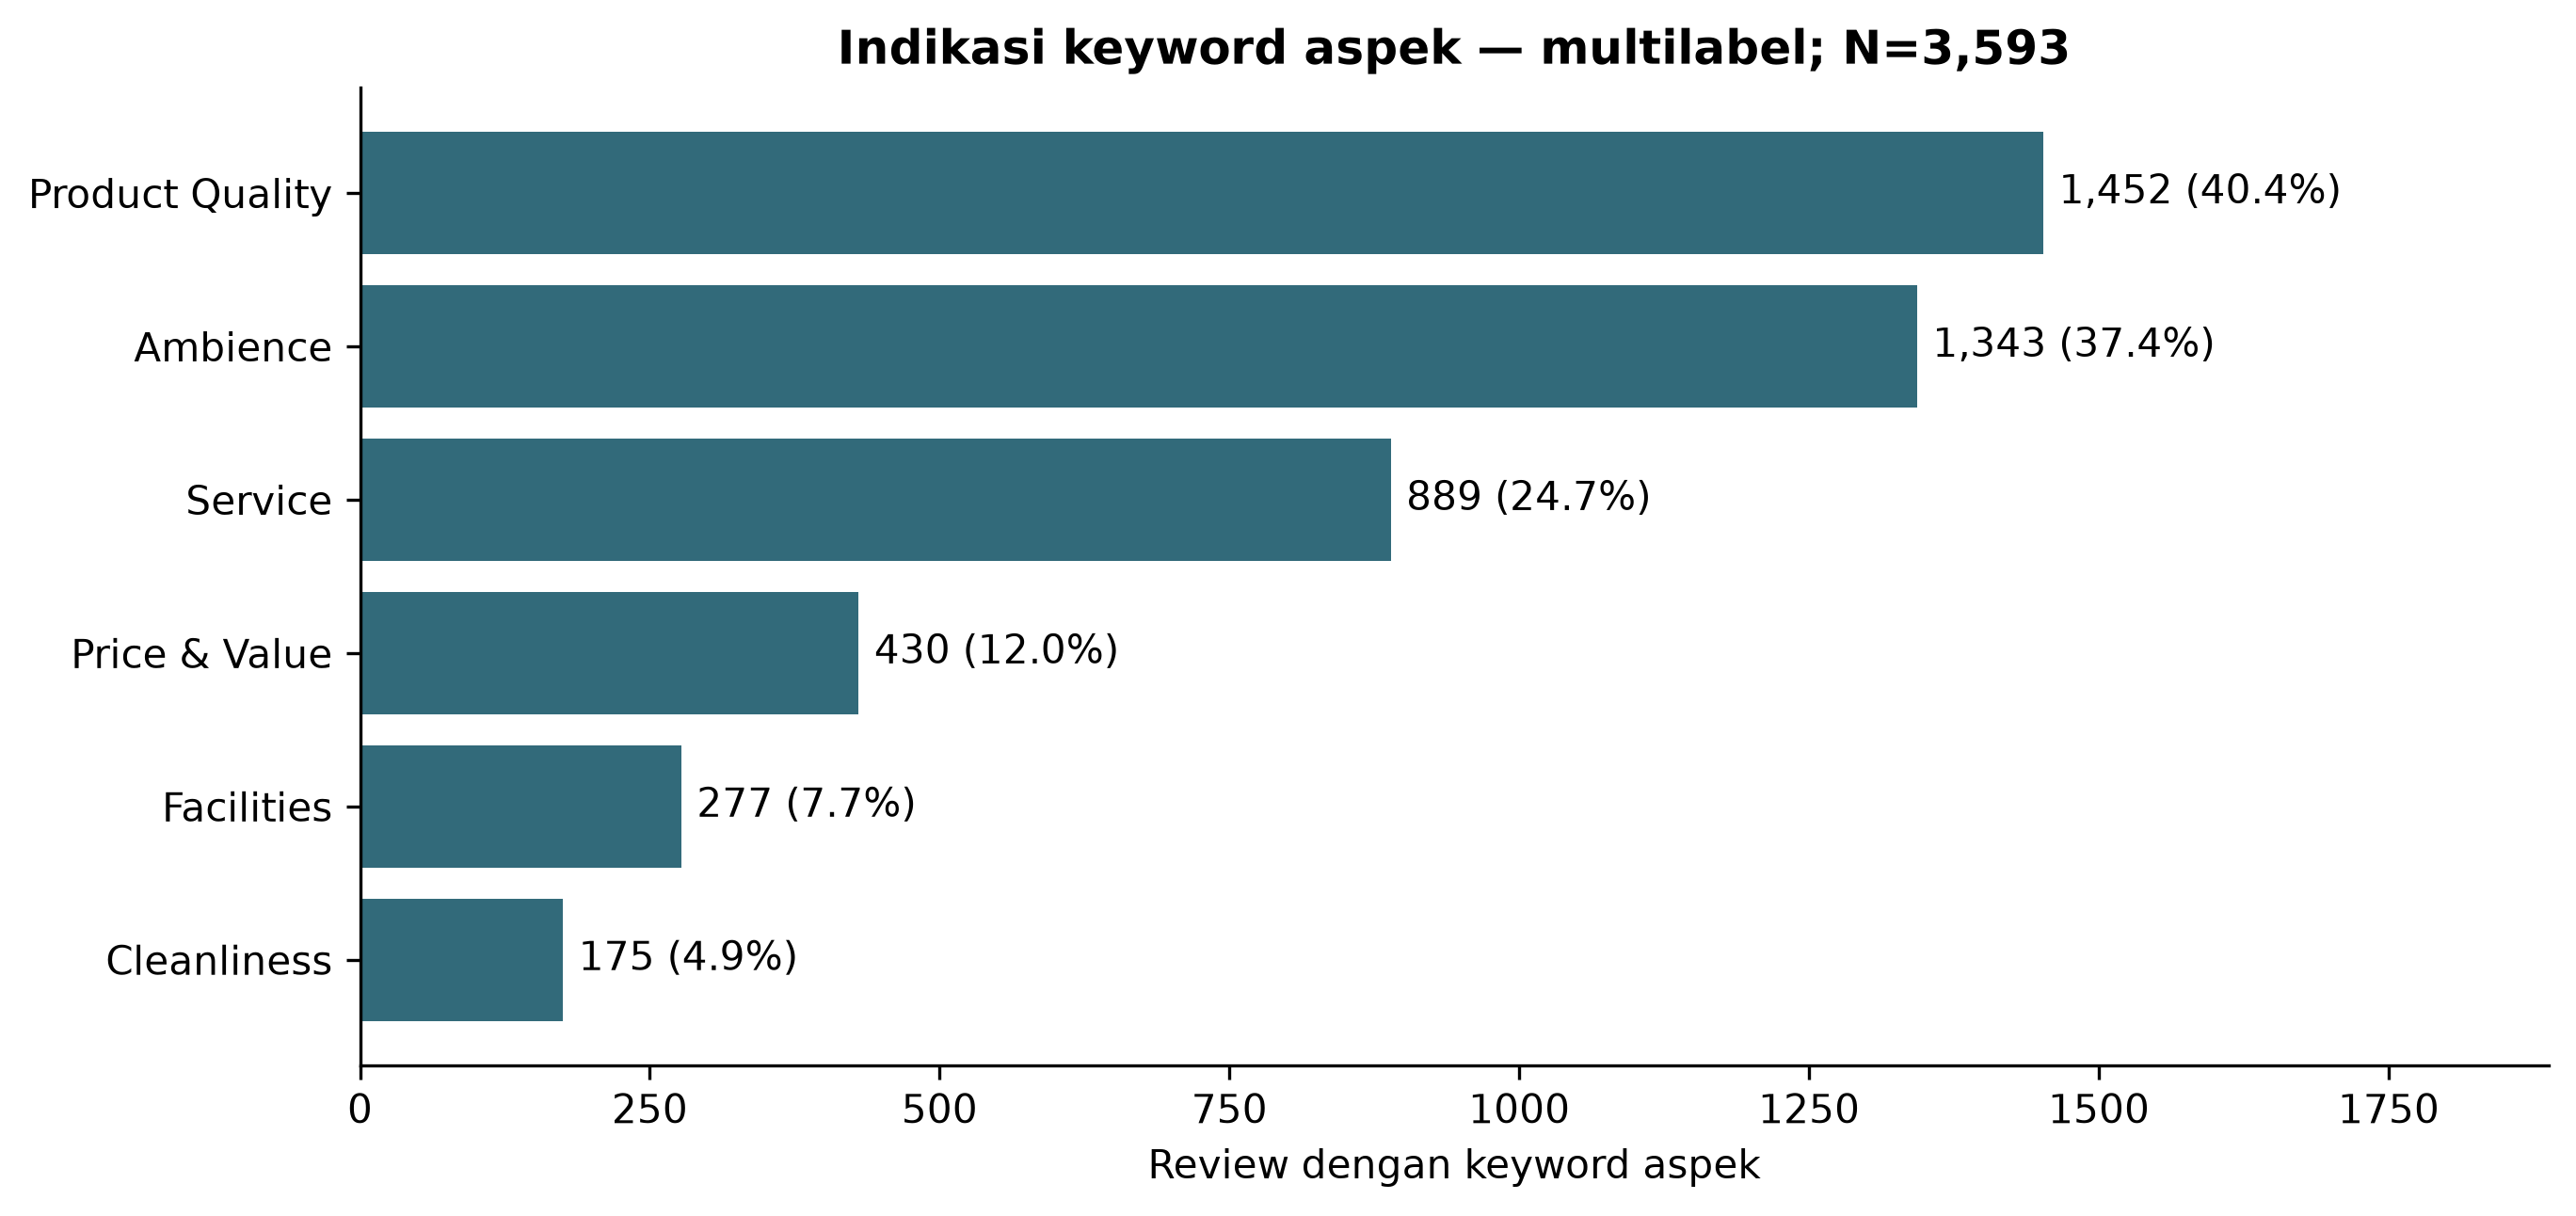

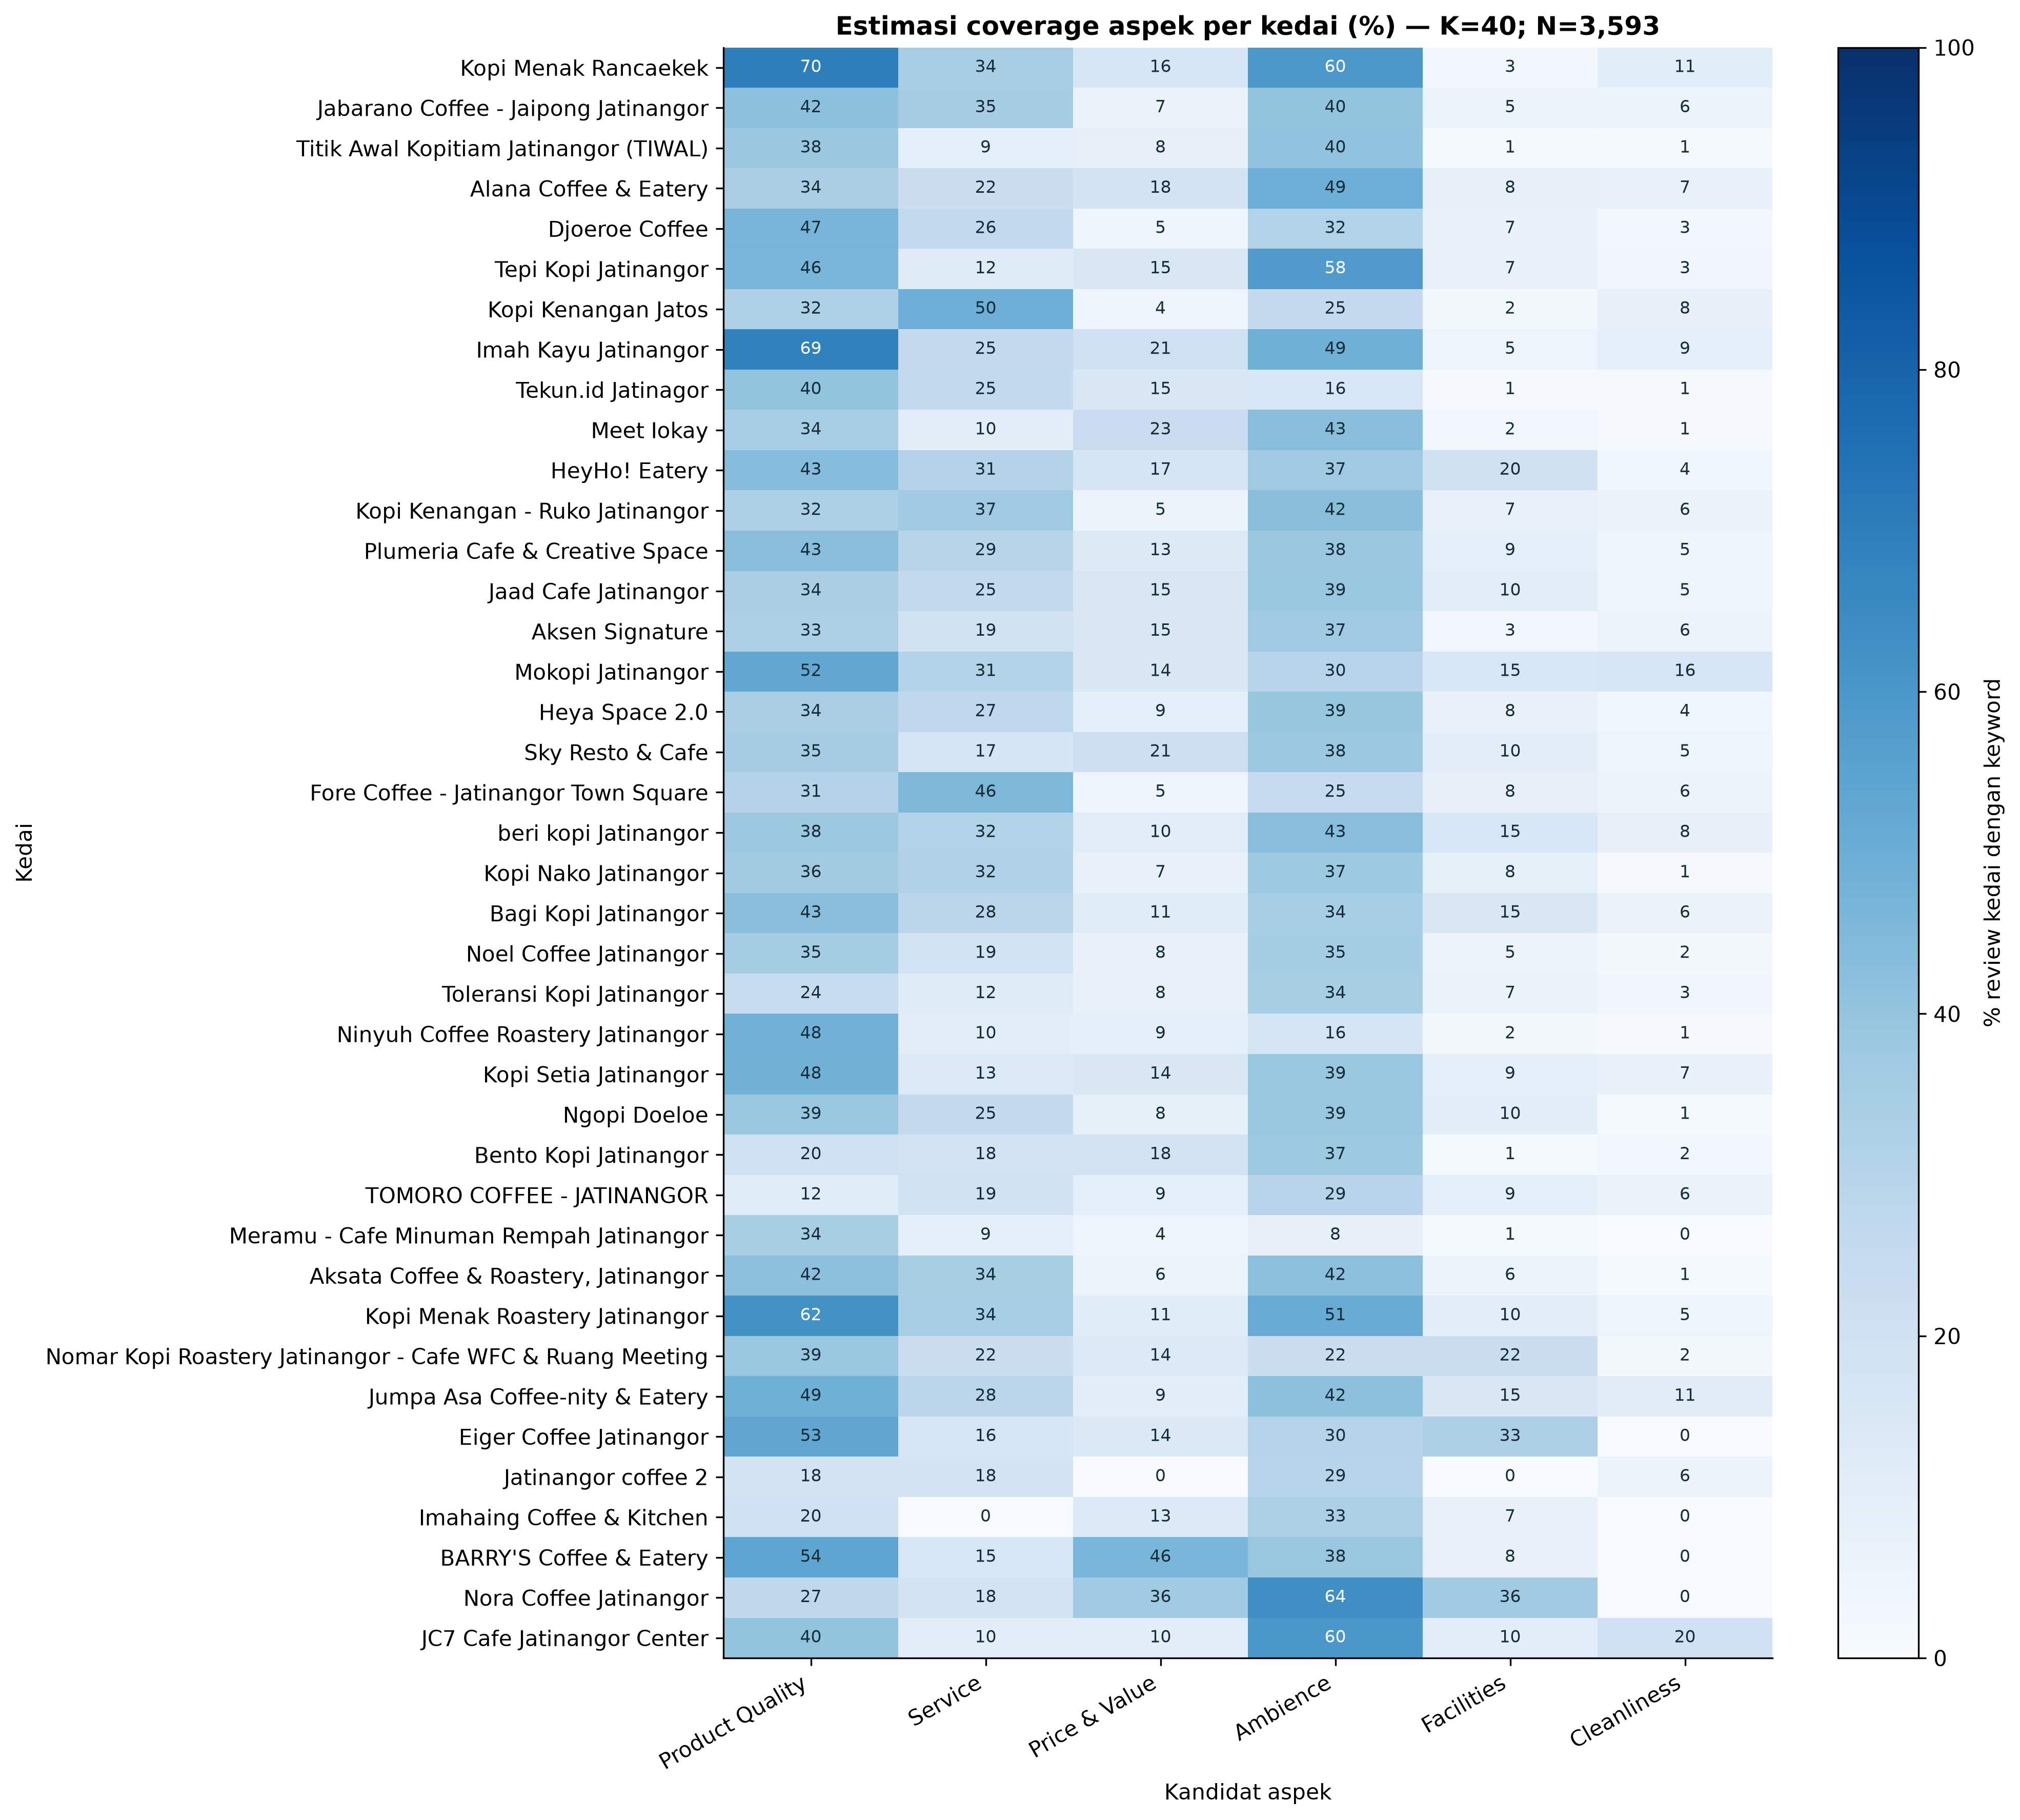

**Interpretasi dan implikasi.** Product Quality: 1,452 (40.41%); Ambience: 1,343 (37.38%); Service: 889 (24.74%); Price & Value: 430 (11.97%); Facilities: 277 (7.71%); Cleanliness: 175 (4.87%). Tanpa keyword: 1,052 (29.28%); indikasi ≥2 aspek: 1,309. Aspek dengan coverage <5%: Cleanliness. Pilot perlu mencakup review tanpa keyword dan aspek jarang untuk menguji recall kamus serta memperbaiki taksonomi. Indikator tidak mengukur kepuasan; sinonim, aspek implisit, dan konteks belum ditangani.

In [11]:
display(pd.DataFrame([
    {"aspect": aspect, "keywords": ", ".join(keywords)} for aspect, keywords in ASPECT_KEYWORDS.items()
]))
mentions = explore_aspects(audit["teks_review"])
aspect_table = mentions.sum().rename_axis("aspect").reset_index(name="review_mentions")
aspect_table["coverage_pct"] = aspect_table["review_mentions"] / N * 100
aspect_counts = mentions.groupby(audit["place_key"]).sum().reindex(places["place_key"])
aspect_pct = aspect_counts.div(places.set_index("place_key")["review_count"], axis=0) * 100
aspect_coverage = (
    aspect_counts.rename_axis("place_key").reset_index()
    .melt(id_vars="place_key", var_name="aspect", value_name="review_mentions")
    .merge(places[["place_key", "nama_tempat", "review_count"]], on="place_key", validate="many_to_one")
)
aspect_coverage["coverage_pct"] = aspect_coverage["review_mentions"] / aspect_coverage["review_count"] * 100
no_keyword_count = int((~mentions.any(axis=1)).sum())
multi_aspect_count = int(mentions.sum(axis=1).ge(2).sum())
display(aspect_table.round(2))
display(aspect_pct.round(1).set_axis(places["nama_tempat"].tolist()))
print("Tanpa keyword:", no_keyword_count, "| ≥2 aspek terindikasi:", multi_aspect_count)
fig, ax = plt.subplots(figsize=(10, 4.5))
ordered = aspect_table.sort_values("review_mentions")
bars = ax.barh(ordered["aspect"], ordered["review_mentions"], color=COLORS["main"])
ax.bar_label(bars, labels=[f"{n:,} ({n/N*100:.1f}%)" for n in ordered["review_mentions"]], padding=4)
ax.margins(x=.3)
ax.set(title=f"Indikasi keyword aspek — multilabel; N={N:,}", xlabel="Review dengan keyword aspek")
save_figure(fig, "aspect_distribution.png")

fig, ax = plt.subplots(figsize=(11, max(10, P * .34)))
matrix = aspect_pct.to_numpy(dtype=float)
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(ASPECT_KEYWORDS)), labels=list(ASPECT_KEYWORDS), rotation=30, ha="right")
ax.set_yticks(range(P), labels=places["nama_tempat"].tolist())
for row in range(P):
    for col in range(len(ASPECT_KEYWORDS)):
        ax.text(col, row, f"{matrix[row, col]:.0f}", ha="center", va="center",
                fontsize=8, color="white" if matrix[row, col] > 55 else "#172D3A")
ax.set(title=f"Estimasi coverage aspek per kedai (%) — K={P}; N={N:,}",
       xlabel="Kandidat aspek", ylabel="Kedai")
fig.colorbar(image, ax=ax, label="% review kedai dengan keyword")
save_figure(fig, "aspect_coverage_heatmap.png")
ranked_aspects = aspect_table.sort_values("review_mentions", ascending=False)
aspect_narrative = "; ".join(
    f"{row.aspect}: {row.review_mentions:,} ({row.coverage_pct:.2f}%)"
    for row in ranked_aspects.itertuples(index=False)
)
rare_aspects = aspect_table.loc[aspect_table["coverage_pct"] < RARE_ASPECT_PCT, "aspect"].tolist()
show_interpretation("Cakupan aspek eksploratif",
    aspect_narrative + f". Tanpa keyword: {no_keyword_count:,} ({no_keyword_count/N*100:.2f}%); "
    f"indikasi ≥2 aspek: {multi_aspect_count:,}. Aspek dengan coverage <{RARE_ASPECT_PCT:g}%: "
    f"{', '.join(rare_aspects) or 'tidak ada'}. Pilot perlu mencakup review tanpa keyword "
    "dan aspek jarang untuk menguji recall kamus serta memperbaiki taksonomi. "
    "Indikator tidak mengukur kepuasan; sinonim, aspek implisit, dan konteks belum ditangani.")


## 10. Dataset Readiness Assessment

**Tujuan.** Membedakan kesiapan teknis, persiapan pilot anotasi, serta kesiapan penggunaan data penelitian.

**Metode.** Critical digunakan untuk integritas field/ID atau prasyarat penggunaan penelitian yang belum terpenuhi. Review simbol/emoji-only adalah **Text Suitability Issue — Symbol/Emoji-only Reviews**, severity **Moderate**: kecil secara proporsi, tetapi perlu keputusan kelayakan teks. Flag asli tetap dipertahankan.

**Geografi dan provenance.** Satu identitas dari URL raw menghasilkan satu baris tabel verifikasi; koordinat kandidat dari daftar lokal tidak mengubah status administratif secara otomatis. Metadata historis yang tidak memiliki bukti dicatat NOT_DOCUMENTED; konfigurasi script saat ini dipisahkan. Izin yang belum terbukti dicatat PERMISSION_NOT_VERIFIED.

**Simulasi eligible.** Semua field lengkap, rating integer 1–5, tanggal valid ≤acuan, URL valid, bukan simbol saja, tanpa konflik ID; salinan rekaman identik dihitung sekali. Review pendek atau teks berulang dengan ID berbeda tetap dipertahankan. Ini simulasi, bukan penghapusan raw atau dataset berlabel.


In [12]:
basic_pass_count = int(audit["passes_basic_quality"].sum())
simulation_mask = audit["passes_basic_quality"] & ~audit["confirmed_duplicate_extra"]
simulated_rows = int(simulation_mask.sum())
# Bukti geografis lokal: pencocokan kandidat, tanpa geocoding/API.
local_places = pd.read_csv(
    PROJECT_ROOT / "data/interim/google_maps_places_jatinangor.csv",
    dtype="string", keep_default_na=False,
)
geographic = geographic_inventory(places, local_places)
geography_counts = geographic["verification_status"].value_counts().reindex(
    ["VERIFIED_INSIDE", "VERIFIED_OUTSIDE", "UNVERIFIED"], fill_value=0
)
display(geographic[[
    "nama_tempat", "latitude", "longitude", "coordinate_status", "verification_status",
]])
display(geography_counts.rename("coffee_shops").to_frame())

provenance = {
    "source_platform": "Google Maps",
    "collection_tool": "Apify",
    "actor_id": "compass/google-maps-reviews-scraper",
    "actor_evidence_basis": "Deklarasi brief pemilik proyek dan Actor ID pada script terkini; tanpa run manifest historis.",
    "dataset_format": "CSV",
    "observation_unit": "Ulasan pelanggan",
    "intended_scope": "Kecamatan Jatinangor, Kabupaten Sumedang, Jawa Barat",
    "observed_unique_places": P,
    "collection_datetime": "NOT_DOCUMENTED",
    "historical_actor_version": "NOT_DOCUMENTED",
    "historical_run_id": "NOT_DOCUMENTED",
    "historical_dataset_id": "NOT_DOCUMENTED",
    "historical_max_reviews": "NOT_DOCUMENTED",
    "historical_processed_place_count": "NOT_DOCUMENTED",
    "historical_place_selection_method": "NOT_DOCUMENTED",
    "historical_empty_text_filter": "NOT_DOCUMENTED",
    "historical_deduplication": "NOT_DOCUMENTED",
    "historical_review_sort_order": "NOT_DOCUMENTED",
    "current_script_configuration": {
        "evidence": "scripts/scrape_google_maps.py; inspeksi source tanpa menjalankan Actor atau membaca .env",
        "max_places_default": 40, "max_reviews_default": 170,
        "language": "id", "personal_data": False, "charge_cap_usd_default": "0.05",
        "filter": "URL https; drop_duplicates URL; head(max_places). Review text/reviewText kosong dilewati.",
        "deduplication": "review_id keep=first setelah normalisasi dan penggabungan CSV.",
        "fallback_id": "SHA-256 placeId|URL|tanggal|teks ketika reviewId tidak tersedia.",
        "historical_configuration_confirmed": False,
    },
    "permission_status": "PERMISSION_NOT_VERIFIED",
    "permission_collection": "PERMISSION_NOT_VERIFIED",
    "permission_storage": "PERMISSION_NOT_VERIFIED",
    "permission_annotation": "PERMISSION_NOT_VERIFIED",
    "permission_training_ml": "PERMISSION_NOT_VERIFIED",
    "permission_publication": "PERMISSION_NOT_VERIFIED",
    "documentation": "docs/research/data_provenance.md",
}
undocumented_metadata = [key for key, value in provenance.items() if value == "NOT_DOCUMENTED"]
provenance_complete = not undocumented_metadata
readiness_dimensions = assess_readiness(
    audit, geographic, provenance["permission_status"], provenance_complete,
)
integrity_issue_rows = readiness_dimensions["technical_data_quality"]["integrity_issue_rows"]
symbol_issue_rows = int(audit["is_symbol_only"].sum())
issues = pd.DataFrame([
    {
        "severity": "Critical", "issue": "Integritas field dan konflik ID", "affected": integrity_issue_rows,
        "status": "PERLU TINDAKAN" if integrity_issue_rows else "LULUS",
        "action": "Periksa missing/validitas/konflik pada review_audit_flags.csv; adjudikasi ke sumber.",
    },
    {
        "severity": "Moderate", "issue": "Text Suitability Issue — Symbol/Emoji-only Reviews",
        "affected": symbol_issue_rows,
        "status": "REVIEW" if symbol_issue_rows else "LULUS",
        "action": "Tinjau kelayakan leksikal untuk ABSA; hanya dikecualikan pada simulasi eligible, tidak dihapus dari raw.",
    },
    {
        "severity": "Critical", "issue": "Wilayah administratif Jatinangor",
        "affected": int(geography_counts["UNVERIFIED"]),
        "status": "BELUM TERVERIFIKASI",
        "action": "Verifikasi alamat/koordinat tiap place ID terhadap batas Kecamatan Jatinangor; jangan putuskan dari nama.",
    },
    {
        "severity": "Moderate", "issue": "Pengulangan teks potensial",
        "affected": int(audit["potential_text_duplicate"].sum()),
        "status": "REVIEW" if audit["potential_text_duplicate"].any() else "LULUS",
        "action": "Bedakan ungkapan sah dan duplikasi melalui ID/metadata; jangan hapus otomatis.",
    },
    {
        "severity": "Moderate", "issue": "Kedai dengan <30 review", "affected": small_count,
        "status": "REVIEW" if small_count else "LULUS",
        "action": "Sampling anotasi per kedai; laporkan ukuran sampel sebelum membandingkan bisnis.",
    },
    {
        "severity": "Moderate", "issue": "Dominasi rating sumber", "affected": int(rating_counts.max()),
        "status": "REVIEW" if rating_counts.max()/N > .7 else "LULUS",
        "action": "Laporkan bias seleksi; jangan konversi rating menjadi label sentimen aspek.",
    },
    {
        "severity": "Moderate", "issue": "Review pendek/bahasa/relevansi",
        "affected": int((audit["is_short_review"] | audit["language_needs_review"] | audit["is_potentially_irrelevant"]).sum()),
        "status": "REVIEW",
        "action": "Tinjau sampel manual termasuk slang, campuran, dan review tanpa keyword; pertahankan teks asli.",
    },
    {
        "severity": "Moderate", "issue": "Privasi teks", "affected": int(audit["needs_privacy_review"].sum()),
        "status": "REVIEW" if audit["needs_privacy_review"].any() else "TIDAK ADA POLA TERDETEKSI",
        "action": "Tinjau PII yang tidak tercakup pola email/telepon sebelum membagi data.",
    },
    {
        "severity": "Moderate", "issue": "Cakupan enam aspek", "affected": len(rare_aspects), "status": "EKSPLORATIF",
        "action": "Tetapkan enam aspek termasuk Cleanliness; pilot manusia untuk mengevaluasi kamus.",
    },
    {
        "severity": "Moderate", "issue": "Metadata historis pengumpulan belum lengkap",
        "affected": len(undocumented_metadata),
        "status": "NOT_DOCUMENTED" if undocumented_metadata else "LULUS",
        "action": "Lengkapi run manifest historis; jangan menganggap default script terbaru sebagai konfigurasi pengumpulan.",
    },
    {
        "severity": "Critical", "issue": "Hak penggunaan data penelitian",
        "affected": 1, "status": provenance["permission_status"],
        "action": "Verifikasi bukti izin pengumpulan, penyimpanan, anotasi, training ML, dan publikasi.",
    },
    {
        "severity": "Minor", "issue": "Sinkronisasi dokumentasi audit", "affected": 0,
        "status": "DIDOKUMENTASIKAN",
        "action": "Gunakan laporan/JSON revisi ini dan tabel geografis; raw dan perhitungan EDA dipertahankan.",
    },
])
readiness = (
    "Teknis: " + readiness_dimensions["technical_data_quality"]["status"]
    + "; Pilot: " + readiness_dimensions["annotation_pilot"]["status"]
    + "; Penggunaan penelitian: " + readiness_dimensions["research_data_usage"]["status"]
)
display(issues)
display(pd.DataFrame([
    {"dimension": key, "status": value["status"], "note": value["note"]}
    for key, value in readiness_dimensions.items()
]))
print("Lolos pemeriksaan kualitas dasar/simulasi eligible:", simulated_rows)
show_interpretation("Kesiapan dataset",
    f"Integritas field/ID bermasalah: {integrity_issue_rows} baris. "
    f"{symbol_issue_rows} review ({symbol_issue_rows/N*100:.2f}%) adalah masalah kelayakan teks "
    "simbol/emoji-only dengan severity Moderate, bukan konflik ID. "
    f"{basic_pass_count:,}/{N:,} baris lolos aturan kualitas dasar; simulasi eligible tetap "
    f"{simulated_rows:,} setelah salinan rekaman identik dihitung sekali. "
    "Review pendek dan teks sama antar-ID tidak dihapus otomatis. "
    f"{readiness}. Persiapan sampel pilot secara teknis dapat dirancang setelah tinjauan "
    "kelayakan teks dan duplikasi; kesiapan ini tidak memberi izin anotasi aktual, training, "
    "atau publikasi. Scope administratif dan izin penggunaan belum terverifikasi; "
    f"{len(undocumented_metadata)} field metadata historis masih NOT_DOCUMENTED.")


,nama_tempat,latitude,longitude,coordinate_status,verification_status
0,Kopi Menak Rancaekek,-6.956003,107.774243,CANDIDATE_NOT_VERIFIED,UNVERIFIED
1,Jabarano Coffee - Jaipong Jatinangor,-6.938923,107.774264,CANDIDATE_NOT_VERIFIED,UNVERIFIED
2,Titik Awal Kopitiam Jatinangor (TIWAL),-6.937437,107.770869,CANDIDATE_NOT_VERIFIED,UNVERIFIED
3,Alana Coffee & Eatery,-6.940888,107.772826,CANDIDATE_NOT_VERIFIED,UNVERIFIED
4,Djoeroe Coffee,-6.937262,107.767913,CANDIDATE_NOT_VERIFIED,UNVERIFIED
5,Tepi Kopi Jatinangor,-6.942986,107.771974,CANDIDATE_NOT_VERIFIED,UNVERIFIED
6,Kopi Kenangan Jatos,-6.934535,107.771426,CANDIDATE_NOT_VERIFIED,UNVERIFIED
7,Imah Kayu Jatinangor,-6.924653,107.784383,CANDIDATE_NOT_VERIFIED,UNVERIFIED
8,Tekun.id Jatinagor,-6.932972,107.775085,CANDIDATE_NOT_VERIFIED,UNVERIFIED
9,Meet Iokay,-6.937452,107.768908,CANDIDATE_NOT_VERIFIED,UNVERIFIED


,coffee_shops
verification_status,
VERIFIED_INSIDE,0
VERIFIED_OUTSIDE,0
UNVERIFIED,40


,severity,issue,affected,status,action
0,Critical,Integritas field dan konflik ID,0,LULUS,Periksa missing/validitas/konflik pada review_...
1,Moderate,Text Suitability Issue — Symbol/Emoji-only Rev...,11,REVIEW,Tinjau kelayakan leksikal untuk ABSA; hanya di...
2,Critical,Wilayah administratif Jatinangor,40,BELUM TERVERIFIKASI,Verifikasi alamat/koordinat tiap place ID terh...
3,Moderate,Pengulangan teks potensial,255,REVIEW,Bedakan ungkapan sah dan duplikasi melalui ID/...
4,Moderate,Kedai dengan <30 review,5,REVIEW,Sampling anotasi per kedai; laporkan ukuran sa...
5,Moderate,Dominasi rating sumber,3071,REVIEW,Laporkan bias seleksi; jangan konversi rating ...
6,Moderate,Review pendek/bahasa/relevansi,1262,REVIEW,"Tinjau sampel manual termasuk slang, campuran,..."
7,Moderate,Privasi teks,0,TIDAK ADA POLA TERDETEKSI,Tinjau PII yang tidak tercakup pola email/tele...
8,Moderate,Cakupan enam aspek,1,EKSPLORATIF,Tetapkan enam aspek termasuk Cleanliness; pilo...
9,Moderate,Metadata historis pengumpulan belum lengkap,10,NOT_DOCUMENTED,Lengkapi run manifest historis; jangan mengang...


,dimension,status,note
0,technical_data_quality,READY,"Simbol/emoji-only adalah kelayakan teks, bukan..."
1,annotation_pilot,CONDITIONALLY_READY_FOR_SAMPLE_PREPARATION,Persiapan rancangan/sampel teknis dimungkinkan...
2,research_data_usage,NOT_READY_PENDING_VERIFICATION,Kesiapan teknis tidak menyatakan izin peneliti...


Lolos pemeriksaan kualitas dasar/simulasi eligible: 3582


**Interpretasi dan implikasi.** Integritas field/ID bermasalah: 0 baris. 11 review (0.31%) adalah masalah kelayakan teks simbol/emoji-only dengan severity Moderate, bukan konflik ID. 3,582/3,593 baris lolos aturan kualitas dasar; simulasi eligible tetap 3,582 setelah salinan rekaman identik dihitung sekali. Review pendek dan teks sama antar-ID tidak dihapus otomatis. Teknis: READY; Pilot: CONDITIONALLY_READY_FOR_SAMPLE_PREPARATION; Penggunaan penelitian: NOT_READY_PENDING_VERIFICATION. Persiapan sampel pilot secara teknis dapat dirancang setelah tinjauan kelayakan teks dan duplikasi; kesiapan ini tidak memberi izin anotasi aktual, training, atau publikasi. Scope administratif dan izin penggunaan belum terverifikasi; 10 field metadata historis masih NOT_DOCUMENTED.

## 11. Key Findings & Research Implications

**Tujuan.** Mengaitkan angka audit dengan rancangan penelitian dan keterbatasannya.

**Metode.** Semua narasi berikut diturunkan dari hasil aktual yang juga dipakai pada grafik dan laporan. Tidak ada angka placeholder.

**Implikasi.** Temuan pada sampel ini belum merupakan kepuasan pelanggan, label sentimen, atau keunggulan bisnis.


In [13]:
for section, text in interpretations.items():
    display(Markdown(f"### {section}\n\n{text}"))
research_limitations = (
    "Sumber adalah ulasan Google Maps melalui Apify sesuai catatan proyek; CSV enam kolom "
    "tidak menyertakan parameter Actor, urutan review, tanggal akuisisi, bukti batas administratif, "
    "atau izin penggunaan. Sampling dipengaruhi daftar tempat, batas volume, ketersediaan "
    "review teks, dan kemungkinan urutan pemilihan. Selection bias dan bias pelanggan yang "
    "menulis review tidak dapat diukur hanya dari CSV. Proporsi rating/aspek adalah statistik "
    "sampel, bukan estimasi populasi. Hak pengambilan, penyimpanan, anotasi, publikasi kutipan, "
    "serta penggunaan penelitian/pelatihan ML perlu diverifikasi dan didokumentasikan. "
    "Audit teknis bukan bukti izin lisensi; lihat docs/research/google_maps_data_acquisition.md. "
    "Rincian bukti lokal dan metadata historis NOT_DOCUMENTED tersedia di "
    "docs/research/data_provenance.md. Konfigurasi script terkini tidak diasumsikan sebagai "
    "konfigurasi historis. Status izin: PERMISSION_NOT_VERIFIED. Koordinat kandidat dari URL "
    "daftar tempat belum membuktikan kecocokan place ID raw atau posisi administratif. "
    "Kamus aspek, bahasa, relevansi, dan privasi memiliki false positive/negative."
)
display(Markdown("**Keterbatasan penelitian.** " + research_limitations))


### Deskripsi dataset

Data berisi 3,593 review, 40 identitas kedai, 40 nama, 3,593 ID unik, dan 40 URL unik. Memori sumber 2.70 MiB. Rentang tanggal 2016-09-13 14:39:50.043000+00:00 hingga 2026-10-25 05:07:03.416000+00:00. Rentang historis panjang tidak membuktikan sampling merata sepanjang waktu. Identitas URL membantu membedakan cabang dengan nama sama.

### Kualitas data

Missing pada enam kolom: 0 sel. Rating invalid 0, tanggal invalid 0, tanggal setelah acuan 0, URL invalid 0. Teks simbol saja 11; pola relevansi rendah 0; indikasi email/telepon 0. Bahasa campuran terindikasi pada 164 review, slang pada 1120; 1019 review tanpa petunjuk Indonesia memerlukan pemeriksaan, bukan penghapusan. Tidak adanya missing tidak membuktikan bebas bias.

### Duplikasi

ID duplikat melibatkan 0 baris; rekaman enam field identik 0 baris. Teks normalisasi berulang di kedai sama 94 baris; lintas kedai 247 baris. Sebanyak 255 baris kandidat merupakan ungkapan ≤10 kata yang mungkin sah. Semua dipertahankan. Deduplikasi memerlukan ID dan metadata; teks identik tidak cukup untuk membatalkan ulasan pelanggan berbeda.

### Distribusi kedai dan geografi

Review per kedai berkisar 10–151; mean 89.83, median 97.50, SD sampel 38.00. Ada 5 kedai <30 review; kedai terbesar menyumbang 4.20% dataset. Petunjuk nama untuk prioritas geografis: Kopi Menak Rancaekek. Seluruh 40 identitas geografis tetap belum terverifikasi. Perbedaan sampel membatasi perbandingan kedai; jumlah besar tidak membuktikan keterwakilan pelanggan. Rancangan anotasi perlu mewakili kedai kecil.

### Karakteristik teks

Mean panjang 15.09 kata (96.64 karakter); median 9.0 kata. Rentang 0–411 kata; SD 22.66. Review <4 kata: 778 (21.65%). P90=33.8; P95=48.0. Anotasi harus mencakup review pendek/panjang; panjang tidak menentukan validitas atau jumlah aspek. Teks asli tidak diubah.

### Rating dan bias sampel

Bintang lima 3,071 (85.47%). Rating tinggi 4–5: 90.34%; rendah 1–2: 6.74%. Mean rating valid 4.64, median 5.0. Korelasi rank rating–panjang -0.286, bersifat deskriptif dan tidak kausal. Dominasi rating tinggi berpotensi membatasi variasi pengalaman dalam sampel. Distribusi sentimen aspek baru diketahui setelah anotasi.

### Cakupan aspek eksploratif

Product Quality: 1,452 (40.41%); Ambience: 1,343 (37.38%); Service: 889 (24.74%); Price & Value: 430 (11.97%); Facilities: 277 (7.71%); Cleanliness: 175 (4.87%). Tanpa keyword: 1,052 (29.28%); indikasi ≥2 aspek: 1,309. Aspek dengan coverage <5%: Cleanliness. Pilot perlu mencakup review tanpa keyword dan aspek jarang untuk menguji recall kamus serta memperbaiki taksonomi. Indikator tidak mengukur kepuasan; sinonim, aspek implisit, dan konteks belum ditangani.

### Kesiapan dataset

Integritas field/ID bermasalah: 0 baris. 11 review (0.31%) adalah masalah kelayakan teks simbol/emoji-only dengan severity Moderate, bukan konflik ID. 3,582/3,593 baris lolos aturan kualitas dasar; simulasi eligible tetap 3,582 setelah salinan rekaman identik dihitung sekali. Review pendek dan teks sama antar-ID tidak dihapus otomatis. Teknis: READY; Pilot: CONDITIONALLY_READY_FOR_SAMPLE_PREPARATION; Penggunaan penelitian: NOT_READY_PENDING_VERIFICATION. Persiapan sampel pilot secara teknis dapat dirancang setelah tinjauan kelayakan teks dan duplikasi; kesiapan ini tidak memberi izin anotasi aktual, training, atau publikasi. Scope administratif dan izin penggunaan belum terverifikasi; 10 field metadata historis masih NOT_DOCUMENTED.

**Keterbatasan penelitian.** Sumber adalah ulasan Google Maps melalui Apify sesuai catatan proyek; CSV enam kolom tidak menyertakan parameter Actor, urutan review, tanggal akuisisi, bukti batas administratif, atau izin penggunaan. Sampling dipengaruhi daftar tempat, batas volume, ketersediaan review teks, dan kemungkinan urutan pemilihan. Selection bias dan bias pelanggan yang menulis review tidak dapat diukur hanya dari CSV. Proporsi rating/aspek adalah statistik sampel, bukan estimasi populasi. Hak pengambilan, penyimpanan, anotasi, publikasi kutipan, serta penggunaan penelitian/pelatihan ML perlu diverifikasi dan didokumentasikan. Audit teknis bukan bukti izin lisensi; lihat docs/research/google_maps_data_acquisition.md. Rincian bukti lokal dan metadata historis NOT_DOCUMENTED tersedia di docs/research/data_provenance.md. Konfigurasi script terkini tidak diasumsikan sebagai konfigurasi historis. Status izin: PERMISSION_NOT_VERIFIED. Koordinat kandidat dari URL daftar tempat belum membuktikan kecocokan place ID raw atau posisi administratif. Kamus aspek, bahasa, relevansi, dan privasi memiliki false positive/negative.

## 12. Conclusions & Recommendations for Stage 3

**Tujuan.** Menghasilkan keputusan tindak lanjut dan artefak terverifikasi.

**Metode.** Ekspor satu baris flag per baris sumber, tabel agregasi, delapan PNG 300 DPI, JSON, dan laporan Markdown dari hasil yang sama. Assertion memeriksa jumlah baris, agregasi rating/aspek, dan hash sumber.

**Rekomendasi.** Verifikasi scope dan hak penggunaan; tetapkan enam aspek; buat guideline, pilot anotasi manusia, agreement, dan adjudikasi. Rancangan AI-assisted labeling pada Tahap 3 perlu gold pilot dan audit kesalahan terlebih dahulu. Tahap ini belum melakukan labeling atau training.


In [14]:
assert len(geographic) == P and geographic["place_key"].is_unique
assert set(geographic["place_key"]) == set(places["place_key"])
assert set(geographic["verification_status"]).issubset(
    {"VERIFIED_INSIDE", "VERIFIED_OUTSIDE", "UNVERIFIED"}
)
assert len(audit) == N
assert int(places["review_count"].sum()) == N
assert len(aspect_coverage) == P * len(ASPECT_KEYWORDS)
assert int(rating_counts.sum()) + int(audit["invalid_rating"].sum()) == N
for aspect in ASPECT_KEYWORDS:
    assert int(aspect_counts[aspect].sum()) == int(mentions[aspect].sum())
assert aspect_coverage["coverage_pct"].between(0, 100).all()
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == SOURCE_SHA256

# Metadata dan flag tetap dapat ditelusuri tanpa menyalin teks ke tabel publik.
excluded = {"teks_review", "normalized_text", "name_normalized", "parsed_date"}
flag_export = audit[[c for c in audit.columns if c not in excluded]].copy()
flag_export.to_csv(FLAGS_PATH, index=False, encoding="utf-8-sig")
places.to_csv(TABLES / "coffee_shop_statistics.csv", index=False, encoding="utf-8-sig")
quality.to_csv(TABLES / "data_quality_summary.csv", index=False, encoding="utf-8-sig")
validity.to_csv(TABLES / "data_validity_summary.csv", index=False, encoding="utf-8-sig")
duplicates.to_csv(TABLES / "duplicate_summary.csv", index=False, encoding="utf-8-sig")
aspect_coverage.to_csv(TABLES / "aspect_coverage.csv", index=False, encoding="utf-8-sig")
aspect_table.to_csv(TABLES / "aspect_distribution.csv", index=False, encoding="utf-8-sig")
rating_table.to_csv(TABLES / "rating_distribution.csv", index=False, encoding="utf-8-sig")
rating_by_place.to_csv(TABLES / "rating_by_place.csv", index=False, encoding="utf-8-sig")
rating_length.to_csv(TABLES / "rating_text_length.csv", encoding="utf-8-sig")
text_stats.to_csv(TABLES / "text_statistics.csv", encoding="utf-8-sig")
length_bands.to_csv(TABLES / "text_length_bands.csv", index=False, encoding="utf-8-sig")
issues.to_csv(TABLES / "readiness_issues.csv", index=False, encoding="utf-8-sig")
geographic.to_csv(TABLES / "geographic_verification.csv", index=False, encoding="utf-8-sig")

FIGURE_NAMES = [
    "review_distribution.png", "top_coffee_shops.png", "rating_distribution.png",
    "review_length_distribution.png", "missing_values.png", "duplicate_analysis.png",
    "aspect_distribution.png", "aspect_coverage_heatmap.png",
]
assert all((FIGURES / name).is_file() for name in FIGURE_NAMES)
summary = {
    "audit_cutoff": AUDIT_CUTOFF.isoformat(),
    "source": RAW_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "source_sha256": SOURCE_SHA256, "raw_unchanged": True, "versions": VERSIONS,
    "overview": overview, "quality": quality.to_dict(orient="records"),
    "validity": validity.to_dict(orient="records"),
    "duplicate_categories": duplicates.to_dict(orient="records"),
    "confirmed_duplicate_extra_rows": int(audit["confirmed_duplicate_extra"].sum()),
    "possible_legitimate_repetition_rows": int(audit["possible_legitimate_repetition"].sum()),
    "per_place_review_statistics": {k: float(v) for k, v in count_stats.items()},
    "small_places_under_30": small_count,
    "geography": {
        "unverified_places": int(geography_counts["UNVERIFIED"]),
        "name_hints_to_verify": geo_hint_names,
        "status_counts": {key: int(value) for key, value in geography_counts.items()},
        "candidate_coordinate_places": int(geographic["latitude"].notna().sum()),
        "evidence_table": "reports/tables/geographic_verification.csv",
        "verification_method": "Inventaris URL raw dan koordinat kandidat lokal; tanpa pencocokan POI/batas yang konklusif.",
    },
    "provenance": provenance,
    "readiness_dimensions": readiness_dimensions,
    "revision": {
        "scope": "Minor finalization Stage 2",
        "symbol_issue_severity": "Moderate",
        "integrity_issue_rows": integrity_issue_rows,
        "symbol_only_rows": symbol_issue_rows,
        "figure_files_reused": not FORCE_REBUILD_FIGURES and previous_summary.get("source_sha256") == SOURCE_SHA256,
    },
    "rating_distribution": rating_table.to_dict(orient="records"),
    "rating_high_pct": high_pct, "rating_low_pct": low_pct,
    "rating_word_spearman": rating_word_rho if np.isfinite(rating_word_rho) else None,
    "text_statistics": json.loads(text_stats.to_json()),
    "text_length_bands": length_bands.to_dict(orient="records"),
    "aspect_distribution": aspect_table.to_dict(orient="records"),
    "aspect_keywords": {key: list(value) for key, value in ASPECT_KEYWORDS.items()},
    "no_aspect_keyword_rows": no_keyword_count, "multi_aspect_keyword_rows": multi_aspect_count,
    "basic_quality_pass_rows": basic_pass_count, "simulated_unique_record_rows": simulated_rows,
    "readiness": readiness, "issues": issues.to_dict(orient="records"),
    "figures": FIGURE_NAMES, "interpretations": interpretations,
}
(REPORTS / "data_audit_summary.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8",
)
recommendations = [
    "Verifikasi seluruh identitas kedai dan bukti administratif Kecamatan Jatinangor; "
    "prioritaskan petunjuk nama wilayah lain tanpa mengasumsikan hasilnya.",
    "Lengkapi provenance Apify: tanggal akuisisi, Actor/versi, urutan, batas volume, "
    "kriteria tempat, dan dasar hak penggunaan penelitian/ML.",
    "Adjudikasi duplikasi potensial melalui ID dan metadata; pertahankan ungkapan pendek sah "
    "sampai ada bukti yang cukup untuk menghapusnya.",
    "Tetapkan enam aspek termasuk Cleanliness; perjelas aspek beririsan, aspek implisit, "
    "serta perbedaan tidak disebutkan dan netral.",
    "Siapkan rancangan pilot manusia yang mewakili kedai kecil/besar, rating bervariasi, "
    "panjang pendek, aspek jarang, dan review tanpa keyword. Anotasi aktual menunggu "
    "penyelesaian scope/izin; kemudian ukur agreement dan adjudikasi.",
    "Rancang AI-assisted labeling berikutnya dengan gold pilot manusia dan audit kesalahan; "
    "jangan gunakan rating sebagai label sentimen aspek.",
    "Jalankan ulang audit setelah keputusan inklusi. Laporan Tahap 2 ini menggantikan "
    "keputusan otomatis lama di reports/data_validation/ yang memakai deduplikasi berbeda.",
]
report_sections = [
    "# Laporan Tahap 2 — Data Audit, Data Understanding & EDA",
    "## 1. Pendahuluan dan tujuan audit\n\nAudit ulasan Google Maps melalui Apify untuk "
    "menyiapkan penelitian ABSA Jatinangor. Entry point: notebooks/01_data_audit_eda.ipynb. "
    f"Tanggal acuan: {AUDIT_CUTOFF.isoformat()}. Tidak dilakukan API, scraping, labeling, atau training.",
    "## 2. Deskripsi dataset\n\n" + interpretations["Deskripsi dataset"] + "\n\n"
    + markdown_table(schema) + f"\n\nSHA-256 sumber: {SOURCE_SHA256}.",
    "## 3. Temuan kualitas data\n\n" + interpretations["Kualitas data"] + "\n\n"
    + markdown_table(quality) + "\n\n" + markdown_table(validity.round(2)) + "\n\n"
    + interpretations["Duplikasi"] + "\n\n" + markdown_table(duplicates.round(2)),
    "## 4. Distribusi coffee shop\n\n" + interpretations["Distribusi kedai dan geografi"]
    + "\n\n### Verifikasi geografis revisi\n\n"
    + markdown_table(geography_counts.rename_axis("verification_status").reset_index(name="coffee_shops"))
    + f"\n\nAda {int(geographic['latitude'].notna().sum())} koordinat kandidat dari URL lokal. "
    "Koordinat tersebut ditautkan berdasarkan kandidat nama saja, belum dikonfirmasi terhadap "
    "place ID raw/poligon administratif. Tidak ada keputusan eksklusi otomatis. Detail: "
    "[geographic_verification.csv](tables/geographic_verification.csv). "
    "Kopi Menak Rancaekek tetap UNVERIFIED; nama tidak menentukan posisi administratif. "
    "Metode dan sumber resmi: [data_provenance.md](../docs/research/data_provenance.md)."
    + "\n\n" + markdown_table(places[[
        "nama_tempat", "review_count", "contribution_pct", "basic_quality_count",
        "short_review_count", "potential_duplicate_count", "mean_rating",
        "mean_word_count", "median_word_count", "review_band",
    ]].round(2)),
    "## 5. Karakteristik review\n\n" + interpretations["Karakteristik teks"] + "\n\n"
    + markdown_table(text_stats.reset_index().rename(columns={"index": "statistic"}))
    + "\n\n" + markdown_table(length_bands.round(2)),
    "## 6. Distribusi rating\n\n" + interpretations["Rating dan bias sampel"] + "\n\n"
    + markdown_table(rating_table.round(2)),
    "## 7. Preliminary aspect coverage\n\n" + interpretations["Cakupan aspek eksploratif"]
    + "\n\n" + markdown_table(aspect_table.round(2))
    + "\n\nKamus dan boundary ada di notebook dan data_audit_summary.json; coverage kedai "
    "tersedia pada tables/aspect_coverage.csv.",
    "## 8. Masalah dan keterbatasan dataset\n\n" + research_limitations
    + "\n\n### Dokumentasi provenance\n\n"
    "Sumber Google Maps; tool Apify; Actor compass/google-maps-reviews-scraper menurut "
    "deklarasi proyek dan script saat ini. Tanggal akuisisi, versi Actor, run ID, dan "
    "konfigurasi historis belum dapat diverifikasi. Default script terbaru: 40 tempat, "
    "170 review/tempat, language=id, personalData=false; bukan bukti input run historis. "
    "Dokumentasi: [data_provenance.md](../docs/research/data_provenance.md). "
    "Izin pengumpulan/penyimpanan/anotasi/training/publikasi: PERMISSION_NOT_VERIFIED.\n\n"
    + markdown_table(pd.DataFrame({
        "metadata_historis": undocumented_metadata, "status": "NOT_DOCUMENTED",
    })),
    "## 9. Dataset readiness assessment\n\n" + interpretations["Kesiapan dataset"]
    + "\n\nAturan simulasi: field lengkap; rating integer 1–5; tanggal valid ≤acuan; "
    "URL Maps valid; bukan simbol saja; tanpa konflik ID; salinan enam field identik "
    "dihitung sekali. Review pendek dan teks berulang antar-ID tetap dipertahankan. "
    "Tidak dihasilkan dataset filtered.\n\n"
    + markdown_table(pd.DataFrame([
        {"dimension": key, "status": value["status"], "note": value["note"]}
        for key, value in readiness_dimensions.items()
    ]))
    + "\n\n" + markdown_table(issues),
    "## 10. Rekomendasi tahap berikutnya\n\n"
    + "\n".join(f"{i}. {item}" for i, item in enumerate(recommendations, 1)),
    "## Visualisasi\n\n" + "\n\n".join(
        f"![{name.replace('_', ' ').replace('.png', '')}](figures/{name})"
        for name in FIGURE_NAMES
    ),
    "## Reproduksibilitas dan pemeriksaan\n\nSeluruh grafik ditampilkan di notebook "
    "dan PNG 300 DPI yang sesuai snapshot sumber/kamus dipakai ulang tanpa ditulis ulang. Flag mempertahankan review_id, place_key, nama, URL, dan nomor "
    "baris sumber. Konservasi jumlah review/rating/aspek dan SHA-256 diperiksa oleh assertion. "
    "Data mentah tidak diubah. Fungsi inti cell audit-core diuji dengan pytest.\n\n"
    + markdown_table(pd.DataFrame(VERSIONS.items(), columns=["package", "version"])),
]
(REPORTS / "data_audit_report.md").write_text("\n\n".join(report_sections) + "\n", encoding="utf-8")
display(Markdown("### Kesimpulan\n\n" + interpretations["Kesiapan dataset"]))
display(Markdown("\n".join(f"{i}. {item}" for i, item in enumerate(recommendations, 1))))
print(f"Artefak: {len(FIGURE_NAMES)} PNG, tabel CSV, JSON, laporan, dan {N:,} baris flag.")
print("SHA-256 sumber terverifikasi.")


### Kesimpulan

Integritas field/ID bermasalah: 0 baris. 11 review (0.31%) adalah masalah kelayakan teks simbol/emoji-only dengan severity Moderate, bukan konflik ID. 3,582/3,593 baris lolos aturan kualitas dasar; simulasi eligible tetap 3,582 setelah salinan rekaman identik dihitung sekali. Review pendek dan teks sama antar-ID tidak dihapus otomatis. Teknis: READY; Pilot: CONDITIONALLY_READY_FOR_SAMPLE_PREPARATION; Penggunaan penelitian: NOT_READY_PENDING_VERIFICATION. Persiapan sampel pilot secara teknis dapat dirancang setelah tinjauan kelayakan teks dan duplikasi; kesiapan ini tidak memberi izin anotasi aktual, training, atau publikasi. Scope administratif dan izin penggunaan belum terverifikasi; 10 field metadata historis masih NOT_DOCUMENTED.

1. Verifikasi seluruh identitas kedai dan bukti administratif Kecamatan Jatinangor; prioritaskan petunjuk nama wilayah lain tanpa mengasumsikan hasilnya.
2. Lengkapi provenance Apify: tanggal akuisisi, Actor/versi, urutan, batas volume, kriteria tempat, dan dasar hak penggunaan penelitian/ML.
3. Adjudikasi duplikasi potensial melalui ID dan metadata; pertahankan ungkapan pendek sah sampai ada bukti yang cukup untuk menghapusnya.
4. Tetapkan enam aspek termasuk Cleanliness; perjelas aspek beririsan, aspek implisit, serta perbedaan tidak disebutkan dan netral.
5. Siapkan rancangan pilot manusia yang mewakili kedai kecil/besar, rating bervariasi, panjang pendek, aspek jarang, dan review tanpa keyword. Anotasi aktual menunggu penyelesaian scope/izin; kemudian ukur agreement dan adjudikasi.
6. Rancang AI-assisted labeling berikutnya dengan gold pilot manusia dan audit kesalahan; jangan gunakan rating sebagai label sentimen aspek.
7. Jalankan ulang audit setelah keputusan inklusi. Laporan Tahap 2 ini menggantikan keputusan otomatis lama di reports/data_validation/ yang memakai deduplikasi berbeda.

Artefak: 8 PNG, tabel CSV, JSON, laporan, dan 3,593 baris flag.
SHA-256 sumber terverifikasi.
